# Stage 2 – AI Governance: Embedding Models Training and Analysis

## Introduction

This notebook presents the second stage of the CTL project. It builds on the cleaned AI Media Dataset from Stage 1 and develops, evaluates and compares text representations for the **AI Governance** topic track.

Two families of models are compared:

1. **Classical embeddings** trained from scratch on the corpus: Word2Vec, FastText and Doc2Vec.
2. **Compact open language models** fine-tuned with parameter-efficient methods: **Qwen3-1.7B** and **Qwen3-4B**, adapted with QLoRA (4-bit quantization + LoRA adapters).

The models are evaluated intrinsically (semantic similarity, clustering quality, visualization) and extrinsically on a task that is directly relevant to the topic track: **multi-label classification of the four AI Governance dimensions** (Security, Accountability, Bias/Fairness, Regulation). Finally, the best model is used to analyse AI Governance discourse beyond the tag-based selection of Stage 1.

**Structure**

0. Setup
1. Data preparation and splits
2. Classical word and document embeddings
3. Baseline classifiers
4. Fine-tuning compact open models (QLoRA)
5. Comparative evaluation and trade-offs
6. Insight extraction for AI Governance
7. Key findings, limitations, AI tool disclosure and contributions

## 0. Setup

The notebook runs locally on a laptop with an NVIDIA RTX 2000 Ada GPU (8 GB). All long-running steps (tokenization, embedding training, fine-tuning, inference) cache their results, so that re-running the notebook reuses trained models instead of retraining them.

In [1]:
import json
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

current_path = Path.cwd()

PROJECT_ROOT = next(
    path for path in [current_path, *current_path.parents]
    if (path / ".git").exists()
)

# Inputs from Stage 1
CORPUS_PATH = PROJECT_ROOT / "data" / "processed" / "corpus" / "ai_media_clean.pkl.gz"
TOPIC_ASSIGNMENTS_PATH = PROJECT_ROOT / "data" / "processed" / "topics" / "ai_governance_topic_assignments.csv"

# Stage 2 outputs
STAGE2_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "stage2"     # splits and caches
MODELS_DIR = PROJECT_ROOT / "outputs" / "models" / "stage2"          # trained models (not in Git)
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results" / "stage2"        # metric tables
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "stage2"

for directory in [STAGE2_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    """Save the current figure as PNG in outputs/figures/stage2."""
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


GOVERNANCE_THEMES = ["security", "accountability", "bias_fairness", "regulation"]
THEME_LABELS = {
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
}

In [2]:
import torch

gpu_available = torch.cuda.is_available()

environment = pd.DataFrame({
    "Item": ["PyTorch", "CUDA available", "GPU", "GPU memory (GB)"],
    "Value": [
        torch.__version__,
        str(gpu_available),
        torch.cuda.get_device_name(0) if gpu_available else "-",
        round(torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1) if gpu_available else "-"
    ]
})

display(environment)

,Item,Value
0,PyTorch,2.11.0+cu128
1,CUDA available,True
2,GPU,NVIDIA RTX 2000 Ada Generation Laptop GPU
3,GPU memory (GB),8.0


## 1. Data Preparation

### 1.1 Loading the Cleaned Corpus

The input is the cleaned and de-duplicated corpus from Stage 1 (47,679 articles). It already contains the four AI Governance theme flags that were derived from the curated tag mapping in Stage 1.

In [3]:
corpus = pd.read_pickle(CORPUS_PATH)

corpus_overview = pd.DataFrame({
    "Metric": [
        "Articles",
        "Governance-related articles",
        "Other articles",
        "Earliest date",
        "Latest date",
        "Total characters (millions)"
    ],
    "Result": [
        len(corpus),
        int(corpus["governance_related"].sum()),
        int((~corpus["governance_related"]).sum()),
        corpus["date"].min().date(),
        corpus["date"].max().date(),
        round(corpus["content_text"].str.len().sum() / 1e6)
    ]
})

display(corpus_overview)

display(
    corpus.loc[corpus["governance_related"], GOVERNANCE_THEMES]
    .sum()
    .rename(index=THEME_LABELS)
    .rename_axis("Governance theme")
    .reset_index(name="Articles")
)

,Metric,Result
0,Articles,47679
1,Governance-related articles,12946
2,Other articles,34733
3,Earliest date,2024-09-11
4,Latest date,2026-09-07
5,Total characters (millions),505


,Governance theme,Articles
0,Security,4455
1,Accountability,7592
2,Bias / Fairness,2662
3,Regulation,1370


### 1.2 Train, Validation and Test Splits

The extrinsic evaluation task is the multi-label classification of the four Governance themes. The labelled data are the 12,946 Governance-related articles; an article can belong to several themes.

The articles are split into **70% training, 15% validation and 15% test** data with a fixed random seed. Because the themes are imbalanced (Regulation is rare) and articles can carry several labels, the split is **stratified by label combination**: each combination of themes (e.g. Security + Regulation) is represented proportionally in all three parts. Very rare combinations are grouped together for stratification.

The test articles are used only for the final evaluation. They are also excluded from training the classical embeddings, so that no model has seen the test texts before. The remaining 34,733 articles without Governance tags are unlabelled; they are used for training the unsupervised embeddings and, in Section 6, for applying the best classifier to articles outside the tag-based Governance subset.

In [4]:
from sklearn.model_selection import train_test_split

SPLIT_PATH = STAGE2_DATA_DIR / "governance_splits.csv"

governance = corpus.loc[corpus["governance_related"]].copy()

# Label combination as stratification key, e.g. "0101"
label_combination = governance[GOVERNANCE_THEMES].astype(int).astype(str).agg("".join, axis=1)
combination_counts = label_combination.map(label_combination.value_counts())
stratify_key = label_combination.where(combination_counts >= 30, "rare")

train_ids, holdout_ids = train_test_split(
    governance["record_id"],
    test_size=0.30,
    stratify=stratify_key,
    random_state=SEED
)

holdout_key = stratify_key.loc[holdout_ids.index]

validation_ids, test_ids = train_test_split(
    holdout_ids,
    test_size=0.50,
    stratify=holdout_key,
    random_state=SEED
)

split_lookup = (
    {record_id: "train" for record_id in train_ids}
    | {record_id: "validation" for record_id in validation_ids}
    | {record_id: "test" for record_id in test_ids}
)

corpus["split"] = corpus["record_id"].map(split_lookup).fillna("unlabelled")

corpus[["record_id", "split"]].to_csv(SPLIT_PATH, index=False)

split_summary = (
    corpus.loc[corpus["governance_related"]]
    .groupby("split")[GOVERNANCE_THEMES]
    .agg(["sum"])
)
split_summary.columns = [THEME_LABELS[column] for column, _ in split_summary.columns]
split_summary.insert(0, "Articles", corpus.loc[corpus["governance_related"], "split"].value_counts())
split_summary = split_summary.loc[["train", "validation", "test"]]

display(split_summary)
print(f"Unlabelled articles: {(corpus['split'] == 'unlabelled').sum():,}")

,Articles,Security,Accountability,Bias / Fairness,Regulation
split,,,,,
train,9062,3118,5315,1863,959
validation,1942,669,1139,399,206
test,1942,668,1138,400,205


Unlabelled articles: 34,733


### 1.3 Text Preprocessing for the Classical Embeddings

Word2Vec, FastText and Doc2Vec learn from sequences of tokens. The article texts are therefore preprocessed as follows:

1. **Sentence splitting** at sentence-ending punctuation, so that word contexts do not cross sentence boundaries.
2. **Tokenization and lowercasing** with a regular expression that keeps words, numbers inside words (e.g. *gpt-4*) and hyphenated terms.
3. **Stop-word removal** (English stop words) and removal of single-character tokens, which carry little semantic information.
4. **Phrase detection** with `gensim.Phrases`: frequent multi-word expressions are merged into single tokens in two passes (bigrams, then trigrams), e.g. *national security* → `national_security` or *red teaming* → `red_teaming`. This is important for the Governance track, where many central concepts consist of several words.

A fast rule-based tokenization is used instead of spaCy lemmatization, because lemmatizing the full corpus of 505 million characters would take several hours. Word2Vec and FastText learn similar vectors for inflected forms anyway, and FastText additionally uses sub-word information.

The phrase models and the embeddings are trained on all articles **except the Governance test split**.

In [5]:
import pickle

from gensim.models.phrases import ENGLISH_CONNECTOR_WORDS, Phrases
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

TOKENS_CACHE_PATH = STAGE2_DATA_DIR / "tokenized_corpus.pkl"
PHRASES_CONFIG = {"min_count": 20, "threshold": 10.0, "passes": 2, "tokenizer": "v1"}

SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
TOKEN_PATTERN = re.compile(r"[a-z][a-z0-9]*(?:[-'][a-z0-9]+)*")
STOP_WORDS = set(ENGLISH_STOP_WORDS)


def tokenize_article(text):
    """Split an article into sentences of lowercase tokens without stop words."""
    sentences = []
    for sentence in SENTENCE_SPLIT.split(text.lower()):
        tokens = [
            token for token in TOKEN_PATTERN.findall(sentence)
            if len(token) > 1 and token not in STOP_WORDS
        ]
        if len(tokens) >= 3:
            sentences.append(tokens)
    return sentences


cache = None
if TOKENS_CACHE_PATH.exists():
    with open(TOKENS_CACHE_PATH, "rb") as file:
        cache = pickle.load(file)
    if cache.get("config") != PHRASES_CONFIG or cache.get("record_ids") != corpus["record_id"].tolist():
        print("Token cache is outdated and is recomputed.")
        cache = None

if cache is None:
    start_time = time.perf_counter()

    article_sentences = [
        tokenize_article(f"{title}. {text}")
        for title, text in zip(corpus["title"], corpus["content_text"])
    ]
    print(f"Tokenization: {(time.perf_counter() - start_time) / 60:.1f} min")

    # Phrase models are learned on all non-test articles
    training_sentences = [
        sentence
        for sentences, split in zip(article_sentences, corpus["split"])
        if split != "test"
        for sentence in sentences
    ]

    bigram_model = Phrases(
        training_sentences,
        min_count=PHRASES_CONFIG["min_count"],
        threshold=PHRASES_CONFIG["threshold"],
        connector_words=ENGLISH_CONNECTOR_WORDS
    ).freeze()

    trigram_model = Phrases(
        (bigram_model[sentence] for sentence in training_sentences),
        min_count=PHRASES_CONFIG["min_count"],
        threshold=PHRASES_CONFIG["threshold"],
        connector_words=ENGLISH_CONNECTOR_WORDS
    ).freeze()

    article_sentences = [
        [trigram_model[bigram_model[sentence]] for sentence in sentences]
        for sentences in article_sentences
    ]
    print(f"Tokenization + phrase detection: {(time.perf_counter() - start_time) / 60:.1f} min")

    cache = {
        "config": PHRASES_CONFIG,
        "record_ids": corpus["record_id"].tolist(),
        "article_sentences": article_sentences
    }
    with open(TOKENS_CACHE_PATH, "wb") as file:
        pickle.dump(cache, file, protocol=pickle.HIGHEST_PROTOCOL)

else:
    print("Tokenized corpus loaded from cache.")

article_sentences = cache["article_sentences"]
corpus["n_tokens"] = [sum(len(sentence) for sentence in sentences) for sentences in article_sentences]

phrase_counts = pd.Series(
    token
    for sentences in article_sentences[:5000]
    for sentence in sentences
    for token in sentence
    if "_" in token
).value_counts()

governance_phrases = [
    phrase for phrase in [
        "eu_ai_act", "ai_act", "artificial_intelligence", "human_rights", "data_protection",
        "red_teaming", "national_security", "executive_order", "responsible_ai", "model_context_protocol"
    ]
    if phrase in phrase_counts.index
]

print(f"\nSentences: {sum(len(sentences) for sentences in article_sentences):,}")
print(f"Tokens: {corpus['n_tokens'].sum():,}")
print(f"Median tokens per article: {corpus['n_tokens'].median():,.0f}")
print(f"\nMost frequent detected phrases (sample of 5,000 articles):")
display(phrase_counts.head(20).rename_axis("Phrase").reset_index(name="Occurrences"))
print(f"Governance-relevant phrases detected: {', '.join(governance_phrases)}")

Tokenized corpus loaded from cache.



Sentences: 3,878,074
Tokens: 36,867,165
Median tokens per article: 596

Most frequent detected phrases (sample of 5,000 articles):


,Phrase,Occurrences
0,generative_ai,3182
1,united_states,2397
2,machine_learning,2272
3,artificial_intelligence,1758
4,use_cases,1506
5,quantum_computing,1170
6,open_source,1129
7,supply_chain,1121
8,data_analytics,895
9,data_center,875


Governance-relevant phrases detected: artificial_intelligence, human_rights, data_protection, red_teaming, national_security, executive_order, model_context_protocol


## 2. Classical Word and Document Embeddings

### 2.1 Training Word2Vec and FastText

Two word-embedding models are trained on all non-test articles:

- **Word2Vec (skip-gram)** learns a vector for every word that occurs at least 10 times, by predicting the surrounding words within a window of five tokens.
- **FastText** uses the same training objective but represents each word additionally as a bag of character n-grams (3–6 characters). It can therefore build vectors for rare or unseen words (e.g. new model names) from their parts.

Both models use 200 dimensions and five training epochs. Training time is recorded for the later comparison of trade-offs.

In [6]:
import multiprocessing

from gensim.models import FastText, Word2Vec

EMBEDDING_PARAMS = {
    "vector_size": 200,
    "window": 5,
    "min_count": 10,
    "sg": 1,
    "epochs": 5,
    "workers": max(1, multiprocessing.cpu_count() - 2),
    "seed": SEED
}

W2V_PATH = MODELS_DIR / "word2vec.model"
FASTTEXT_PATH = MODELS_DIR / "fasttext.model"
TRAINING_TIMES_PATH = RESULTS_DIR / "training_times.json"

training_times = json.loads(TRAINING_TIMES_PATH.read_text()) if TRAINING_TIMES_PATH.exists() else {}

embedding_sentences = [
    sentence
    for sentences, split in zip(article_sentences, corpus["split"])
    if split != "test"
    for sentence in sentences
]
print(f"Training sentences: {len(embedding_sentences):,}")


def train_or_load(model_class, path, name, **extra_params):
    if path.exists():
        print(f"{name} loaded from {path.name}")
        return model_class.load(str(path))
    start_time = time.perf_counter()
    model = model_class(sentences=embedding_sentences, **EMBEDDING_PARAMS, **extra_params)
    training_times[name] = round(time.perf_counter() - start_time, 1)
    model.save(str(path))
    TRAINING_TIMES_PATH.write_text(json.dumps(training_times, indent=2))
    print(f"{name} trained in {training_times[name] / 60:.1f} min")
    return model


w2v_model = train_or_load(Word2Vec, W2V_PATH, "Word2Vec")
fasttext_model = train_or_load(FastText, FASTTEXT_PATH, "FastText", min_n=3, max_n=6)

print(f"\nWord2Vec vocabulary: {len(w2v_model.wv):,} words")
print(f"FastText vocabulary: {len(fasttext_model.wv):,} words (+ character n-grams)")

Training sentences: 3,699,359
Word2Vec loaded from word2vec.model


FastText loaded from fasttext.model



Word2Vec vocabulary: 122,983 words
FastText vocabulary: 122,983 words (+ character n-grams)


### 2.2 Training Doc2Vec

Doc2Vec (PV-DBOW) learns one vector per **article** that predicts the words of the article. Unlike averaged word vectors, the document vector is optimized directly to represent the whole text. Training uses all non-test articles; vectors for validation and test articles are **inferred** with the trained model, so that their texts do not influence training.

In [7]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

D2V_PATH = MODELS_DIR / "doc2vec.model"

article_tokens = [
    [token for sentence in sentences for token in sentence]
    for sentences in article_sentences
]

if D2V_PATH.exists():
    d2v_model = Doc2Vec.load(str(D2V_PATH))
    print("Doc2Vec loaded from cache.")
else:
    tagged_documents = [
        TaggedDocument(tokens, [str(record_id)])
        for tokens, record_id, split in zip(article_tokens, corpus["record_id"], corpus["split"])
        if split != "test"
    ]
    start_time = time.perf_counter()
    d2v_model = Doc2Vec(
        documents=tagged_documents,
        vector_size=200,
        dm=0,
        min_count=10,
        epochs=10,
        workers=EMBEDDING_PARAMS["workers"],
        seed=SEED
    )
    training_times["Doc2Vec"] = round(time.perf_counter() - start_time, 1)
    d2v_model.save(str(D2V_PATH))
    TRAINING_TIMES_PATH.write_text(json.dumps(training_times, indent=2))
    print(f"Doc2Vec trained in {training_times['Doc2Vec'] / 60:.1f} min")

print(f"Document vectors learned: {len(d2v_model.dv):,}")

Doc2Vec loaded from cache.
Document vectors learned: 45,737


### 2.3 Document Representations

For the comparisons below, every Governance article is represented as a 200-dimensional vector in four ways:

| Representation | How the article vector is built |
|---|---|
| **TF-IDF + SVD** | TF-IDF weights of words and bigrams (fitted on the training split), reduced to 200 dimensions with truncated SVD |
| **Word2Vec (mean)** | average of the Word2Vec vectors of all tokens in the article |
| **FastText (mean)** | average of the FastText vectors of all tokens |
| **Doc2Vec** | inferred PV-DBOW document vector (validation and test articles) or learned vector (training articles) |

TF-IDF serves as a strong classical reference that does not use embeddings.

In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

DOC_VECTORS_PATH = STAGE2_DATA_DIR / "governance_document_vectors.npz"

gov_mask = corpus["governance_related"].values
gov_index = np.where(gov_mask)[0]
gov = corpus.iloc[gov_index].reset_index(drop=True)
gov_tokens = [article_tokens[i] for i in gov_index]
gov_split = gov["split"].values


def mean_vector(keyed_vectors, tokens):
    vectors = [keyed_vectors[token] for token in tokens if token in keyed_vectors]
    return np.mean(vectors, axis=0) if vectors else np.zeros(keyed_vectors.vector_size)


import joblib

TFIDF_PATH = MODELS_DIR / "tfidf_svd.joblib"


def identity(tokens):
    return tokens


if DOC_VECTORS_PATH.exists() and TFIDF_PATH.exists():
    doc_vectors = dict(np.load(DOC_VECTORS_PATH))
    tfidf, svd = joblib.load(TFIDF_PATH)
    print("Document vectors loaded from cache.")
else:
    start_time = time.perf_counter()
    doc_vectors = {}

    # TF-IDF fitted on the training split only
    tfidf = TfidfVectorizer(
        analyzer=identity, min_df=5, max_df=0.8, max_features=50000
    )
    tfidf_train = tfidf.fit_transform([t for t, s in zip(gov_tokens, gov_split) if s == "train"])
    svd = TruncatedSVD(n_components=200, random_state=SEED).fit(tfidf_train)
    joblib.dump((tfidf, svd), TFIDF_PATH)
    doc_vectors["tfidf_svd"] = svd.transform(tfidf.transform(gov_tokens))

    doc_vectors["word2vec_mean"] = np.vstack([mean_vector(w2v_model.wv, t) for t in gov_tokens])
    doc_vectors["fasttext_mean"] = np.vstack([mean_vector(fasttext_model.wv, t) for t in gov_tokens])

    doc_vectors["doc2vec"] = np.vstack([
        d2v_model.dv[str(record_id)] if split == "train"
        else d2v_model.infer_vector(tokens, epochs=20)
        for record_id, split, tokens in zip(gov["record_id"], gov_split, gov_tokens)
    ])

    np.savez_compressed(DOC_VECTORS_PATH, **doc_vectors)
    print(f"Document vectors computed in {(time.perf_counter() - start_time) / 60:.1f} min")

for name, matrix in doc_vectors.items():
    print(f"{name:15s} {matrix.shape}")

Document vectors loaded from cache.
tfidf_svd       (12946, 200)
word2vec_mean   (12946, 200)
fasttext_mean   (12946, 200)
doc2vec         (12946, 200)


### 2.4 Intrinsic Evaluation: Nearest Neighbours of Governance Terms

A first qualitative check is whether the embeddings place Governance concepts close to semantically related terms. The table lists the five nearest neighbours (cosine similarity) of central Governance terms in both models.

In [9]:
QUERY_TERMS = [
    "accountability", "transparency", "regulation", "gdpr", "bias",
    "privacy", "deepfake", "surveillance", "copyright", "agent"
]


def neighbours(keyed_vectors, term, topn=5):
    if term not in keyed_vectors.key_to_index:
        return "(not in vocabulary)"
    return ", ".join(word for word, _ in keyed_vectors.most_similar(term, topn=topn))


neighbour_table = pd.DataFrame({
    "Term": QUERY_TERMS,
    "Word2Vec": [neighbours(w2v_model.wv, term) for term in QUERY_TERMS],
    "FastText": [neighbours(fasttext_model.wv, term) for term in QUERY_TERMS]
})

with pd.option_context("display.max_colwidth", None):
    display(neighbour_table)

,Term,Word2Vec,FastText
0,accountability,"clear_accountability, transparency_accountability, oversight, transparency_explainability, transparency_auditability","clear_accountability, transparency_accountability, algorithmic_accountability, oversight_accountability, accountability_transparency"
1,transparency,"transparency_accountability, greater_transparency, transparency_auditability, accountability, fairness_accountability","transparence, transparency_auditability, transparency_accountability, transparency_fairness, accountability_transparency"
2,regulation,"micar, regulatory_framework, european_union's, crypto-assets, dodd-frank","pro-regulation, regulations, overregulation, dysregulation, over-regulation"
3,gdpr,"general_data_protection, regulation_gdpr, ccpa, california_consumer_privacy, like_gdpr","hipaa_gdpr, gdpr_ccpa, laws_gdpr, fdpr, gdpr_hipaa"
4,bias,"biases, potential_biases, algorithmic_bias, biased, bias_discrimination","biases, racial_bias, biased, arbias, fairness_bias"
5,privacy,"privacy_security, data_privacy, privacy_protection, security_privacy, user_privacy","jax-privacy, data_privacy, privacy_security, user_privacy, privacy-safe"
6,deepfake,"deepfakes, deepfake_videos, impersonations, non-consensual, fake_videos","deepfaked, deepfakes, deepfake_videos, deepface, deepfake_fraud"
7,surveillance,"border_surveillance, body-worn, alpr, predictive_policing, surveil","drone_surveillance, surveilling, surveil, surveilled, border_surveillance"
8,copyright,"copyright_law, infringement, use_copyrighted, fair_use, copyright_trademark","copyrights, copyrighted, copyrightable, copyrightability, copyright_law"
9,agent,"agents, agent_executes, subagent, sub-agent, agent_runtime","cagent, agents, swe-agent, subagent, kagent"


**Observations**

- The neighbours of all ten terms are thematically coherent in both models: *bias* → *algorithmic_bias*, *bias_discrimination*; *gdpr* → *ccpa*, *california_consumer_privacy*; *surveillance* → *predictive_policing*, *border_surveillance*.
- Word2Vec returns more **related concepts** (e.g. *regulation* → *regulatory_framework*, *dodd-frank*), while FastText, which uses sub-word information, mainly returns **spelling variants** of the same word (*regulation* → *regulations*, *over-regulation*; *copyright* → *copyrights*, *copyrightable*).
- Word2Vec is therefore more useful for exploring the Governance vocabulary, FastText for robustness against rare and misspelled word forms.

### 2.5 Intrinsic Evaluation: Word-Pair Similarity

To quantify semantic quality, a small Governance-specific word-pair test is used. It contains pairs that should be **related** (e.g. *regulation – legislation*, *deepfake – disinformation*) and pairs that should be **unrelated** (e.g. *regulation – battery*).

Two measures are reported:

- the average cosine similarity of related and unrelated pairs, and
- the **pairwise accuracy**: the share of all (related, unrelated) pair combinations in which the related pair receives the higher similarity.

The word pairs were compiled for this project and are small in number; the test is therefore a plausibility check rather than a standard benchmark.

In [10]:
RELATED_PAIRS = [
    ("regulation", "legislation"), ("privacy", "data_protection"), ("bias", "discrimination"),
    ("deepfake", "disinformation"), ("surveillance", "facial_recognition"), ("accountability", "transparency"),
    ("security", "cybersecurity"), ("lawmakers", "legislators"), ("fine", "penalty"),
    ("copyright", "intellectual_property"), ("safety", "risk"), ("compliance", "regulatory"),
    ("fairness", "equity"), ("misinformation", "disinformation"), ("lawsuit", "court")
]

UNRELATED_PAIRS = [
    ("regulation", "battery"), ("privacy", "recipe"), ("bias", "smartphone"),
    ("deepfake", "spreadsheet"), ("surveillance", "football"), ("accountability", "chip"),
    ("security", "garden"), ("lawmakers", "pixel"), ("fine", "satellite"),
    ("copyright", "vaccine"), ("safety", "wallpaper"), ("compliance", "guitar"),
    ("fairness", "rocket"), ("misinformation", "keyboard"), ("lawsuit", "battery")
]


def pair_similarities(keyed_vectors, pairs, allow_oov=False):
    values = []
    for a, b in pairs:
        if allow_oov or (a in keyed_vectors.key_to_index and b in keyed_vectors.key_to_index):
            values.append(float(keyed_vectors.similarity(a, b)))
    return np.array(values)


def word_pair_scores(keyed_vectors, allow_oov=False):
    related = pair_similarities(keyed_vectors, RELATED_PAIRS, allow_oov)
    unrelated = pair_similarities(keyed_vectors, UNRELATED_PAIRS, allow_oov)
    pairwise_accuracy = (related[:, None] > unrelated[None, :]).mean()
    return {
        "Related pairs found": len(related),
        "Unrelated pairs found": len(unrelated),
        "Mean similarity (related)": round(related.mean(), 3),
        "Mean similarity (unrelated)": round(unrelated.mean(), 3),
        "Pairwise accuracy": round(pairwise_accuracy, 3)
    }


word_pair_results = pd.DataFrame({
    "Word2Vec": word_pair_scores(w2v_model.wv),
    "FastText": word_pair_scores(fasttext_model.wv, allow_oov=True)
}).T

display(word_pair_results)

,Related pairs found,Unrelated pairs found,Mean similarity (related),Mean similarity (unrelated),Pairwise accuracy
Word2Vec,15.0,15.0,0.591,0.136,1.0
FastText,15.0,15.0,0.638,0.143,1.0


**Observations**

- Both models rank every related pair above every unrelated pair (pairwise accuracy 1.0); all 30 pairs are in the vocabulary.
- FastText separates the two groups slightly more clearly (mean similarity 0.638 vs. 0.143) than Word2Vec (0.591 vs. 0.136).
- With only 30 pairs the test confirms that both embeddings capture the Governance vocabulary, but it is too small to declare one model clearly better.

### 2.6 Intrinsic Evaluation: Clustering Quality of Document Vectors

A good document representation should place articles about the same topic close together. Two clustering measures are computed on the Governance articles:

- **Silhouette score by Governance theme:** for articles with exactly one Governance theme (about 80% of the Governance articles), it measures how well articles of the same theme are separated from articles of other themes (range −1 to 1; higher is better).
- **Agreement with the Stage 1 topics:** the articles are clustered into eight groups with k-means, and the clusters are compared with the eight NMF topics from Stage 1 using the normalized mutual information (NMI, 0 to 1; higher means more similar groupings).

Both measures use cosine geometry (vectors are L2-normalized).

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import normalize

topic_assignments = pd.read_csv(TOPIC_ASSIGNMENTS_PATH)
gov_topics = gov["record_id"].map(topic_assignments.set_index("record_id")["dominant_topic"]).values

single_theme = gov[GOVERNANCE_THEMES].sum(axis=1).values == 1
single_theme_label = gov[GOVERNANCE_THEMES].values.argmax(axis=1)

clustering_rng = np.random.default_rng(SEED)
silhouette_sample = clustering_rng.choice(np.where(single_theme)[0], size=5000, replace=False)


def clustering_scores(matrix):
    normalized = normalize(matrix)
    silhouette = silhouette_score(
        normalized[silhouette_sample], single_theme_label[silhouette_sample], metric="cosine"
    )
    clusters = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit_predict(normalized)
    return {
        "Silhouette (Governance themes)": round(silhouette, 3),
        "NMI with Stage 1 topics": round(normalized_mutual_info_score(gov_topics, clusters), 3)
    }


REPRESENTATION_NAMES = {
    "tfidf_svd": "TF-IDF + SVD",
    "word2vec_mean": "Word2Vec (mean)",
    "fasttext_mean": "FastText (mean)",
    "doc2vec": "Doc2Vec"
}

clustering_results = pd.DataFrame({
    REPRESENTATION_NAMES[name]: clustering_scores(matrix)
    for name, matrix in doc_vectors.items()
}).T

display(clustering_results)

,Silhouette (Governance themes),NMI with Stage 1 topics
TF-IDF + SVD,0.019,0.455
Word2Vec (mean),0.036,0.349
FastText (mean),0.031,0.311
Doc2Vec,0.018,0.363


**Observations**

- All silhouette scores are close to 0 (0.018–0.036): in all four representations, articles of different Governance themes **overlap strongly**. This is plausible because many articles touch on several themes, and the themes share vocabulary (e.g. *risk*, *policy*, *data*).
- The averaged word embeddings separate the themes slightly better (Word2Vec 0.036, FastText 0.031) than TF-IDF + SVD (0.019) and Doc2Vec (0.018).
- TF-IDF + SVD agrees most with the Stage 1 NMF topics (NMI 0.455). This is expected, since the NMF topics were also derived from word-frequency features.

### 2.7 Visualization of Governance Concepts

The following map shows the Word2Vec neighbourhoods of eight Governance seed terms, projected to two dimensions with UMAP. Each colour corresponds to one seed term and its 12 nearest neighbours. Clearly separated groups indicate that the embedding distinguishes the Governance concepts; overlapping groups indicate concepts that are discussed in similar contexts.

C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


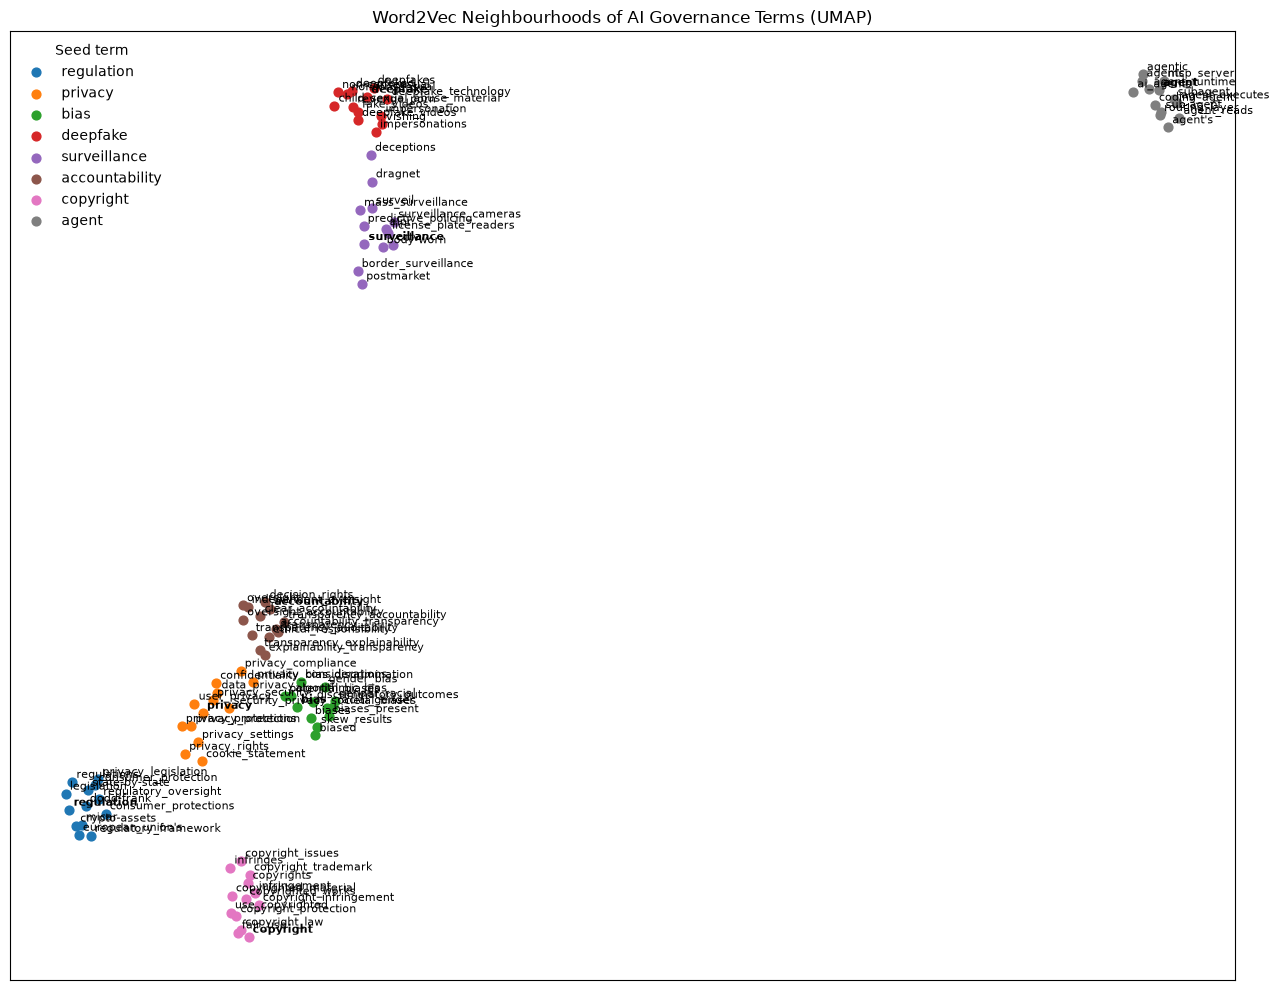

In [12]:
import umap

SEED_TERMS = ["regulation", "privacy", "bias", "deepfake", "surveillance", "accountability", "copyright", "agent"]

words, groups = [], []
for seed_term in SEED_TERMS:
    if seed_term not in w2v_model.wv.key_to_index:
        continue
    for word in [seed_term] + [w for w, _ in w2v_model.wv.most_similar(seed_term, topn=12)]:
        if word not in words:
            words.append(word)
            groups.append(seed_term)

word_coordinates = umap.UMAP(
    n_neighbors=10, min_dist=0.3, metric="cosine", random_state=SEED
).fit_transform(np.vstack([w2v_model.wv[word] for word in words]))

fig, ax = plt.subplots(figsize=(13, 10))
colors = plt.get_cmap("tab10")

for i, seed_term in enumerate(SEED_TERMS):
    idx = [j for j, group in enumerate(groups) if group == seed_term]
    ax.scatter(word_coordinates[idx, 0], word_coordinates[idx, 1], color=colors(i), label=seed_term, s=40)
    for j in idx:
        ax.annotate(
            words[j], word_coordinates[j],
            fontsize=8, fontweight="bold" if words[j] == seed_term else "normal",
            xytext=(3, 3), textcoords="offset points"
        )

ax.set_title("Word2Vec Neighbourhoods of AI Governance Terms (UMAP)")
ax.legend(title="Seed term", frameon=False, loc="best")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
save_figure("word2vec_governance_terms_umap")
plt.show()

**Observations**

- The eight seed terms form **clearly separated groups**, so Word2Vec distinguishes the Governance concepts.
- *Accountability*, *privacy* and *bias* lie close together and partly overlap. These concepts often appear together in responsible-AI articles (e.g. *transparency_accountability*).
- *Agent* forms an isolated group far away from all other terms: in this corpus, it is discussed in a technical context (*subagent*, *agent_runtime*, *mcp_server*) rather than in a Governance context.

The next figure projects the document vectors of the Governance articles with exactly one Governance theme into two dimensions, separately for each representation. It shows visually how well each representation separates the four themes.

C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


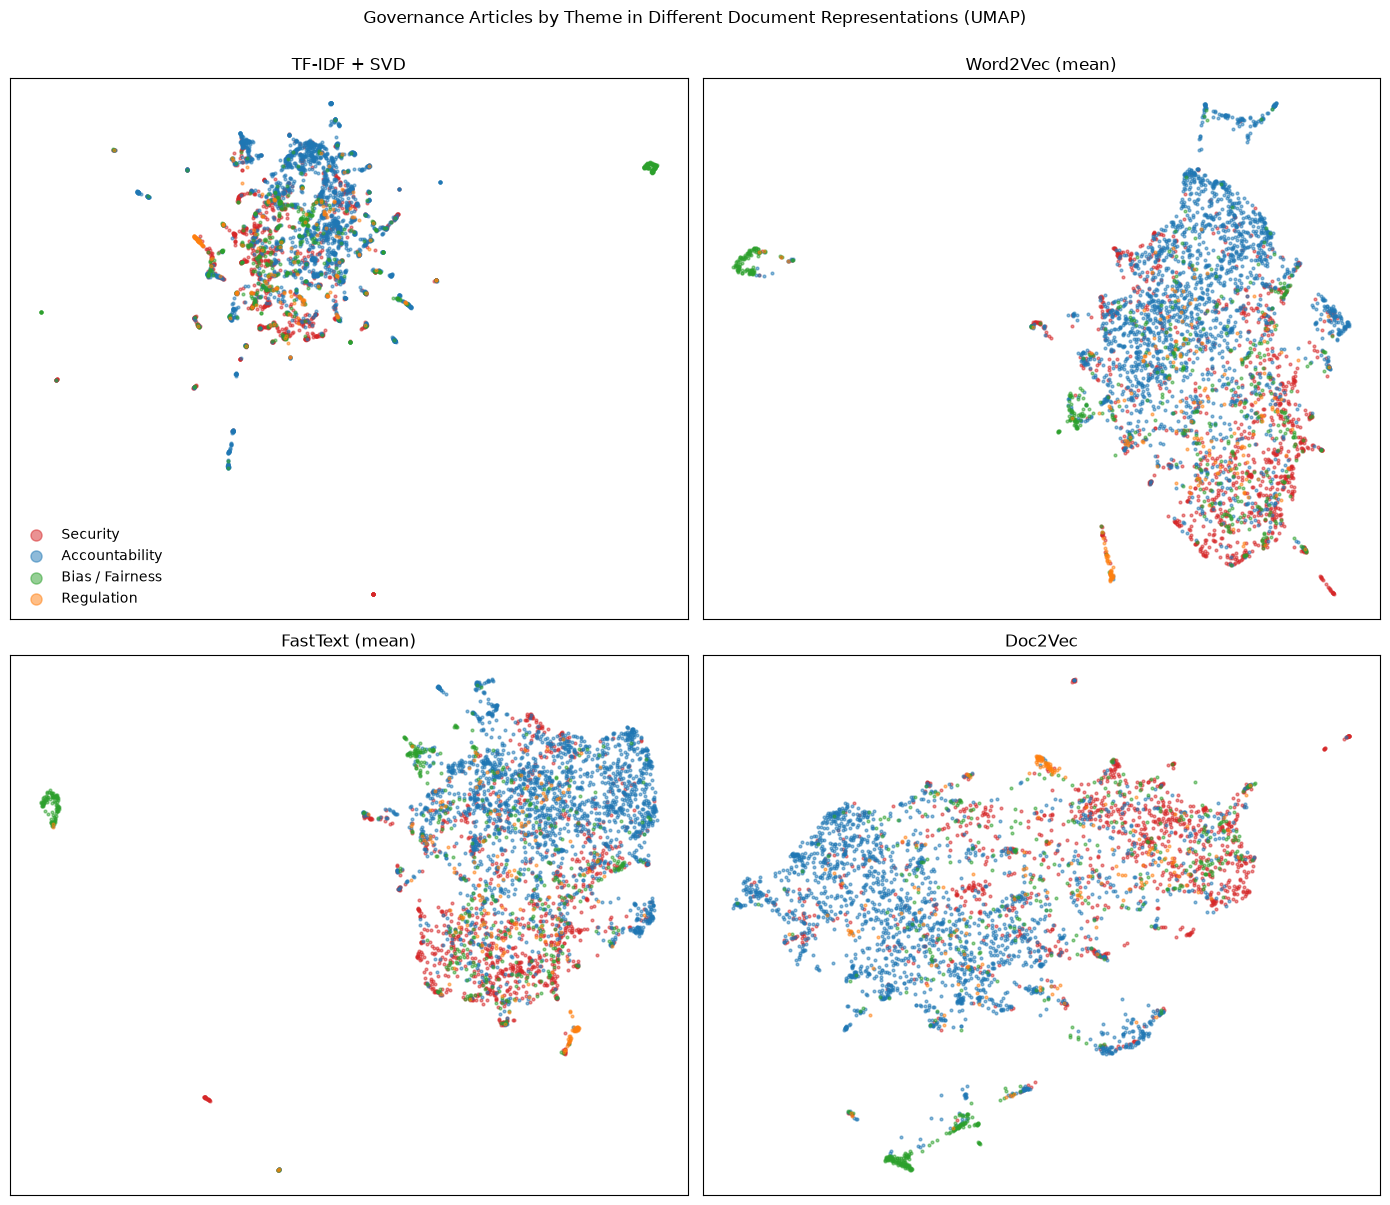

In [13]:
plot_sample = clustering_rng.choice(np.where(single_theme)[0], size=4000, replace=False)
theme_colors = {0: "tab:red", 1: "tab:blue", 2: "tab:green", 3: "tab:orange"}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, matrix) in zip(axes.ravel(), doc_vectors.items()):
    coordinates = umap.UMAP(
        n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED
    ).fit_transform(normalize(matrix[plot_sample]))
    labels = single_theme_label[plot_sample]
    for theme_index, theme in enumerate(GOVERNANCE_THEMES):
        mask = labels == theme_index
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=4, alpha=0.5,
                   color=theme_colors[theme_index], label=THEME_LABELS[theme])
    ax.set_title(REPRESENTATION_NAMES[name])
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].legend(markerscale=4, frameon=False)
fig.suptitle("Governance Articles by Theme in Different Document Representations (UMAP)", y=1.0)

plt.tight_layout()
save_figure("document_representations_umap")
plt.show()

**Observations**

- In all four representations, the large majority of articles forms **one mixed cloud** in which the themes overlap, consistent with the low silhouette scores.
- A coarse structure is visible in Word2Vec, FastText and Doc2Vec: Accountability articles concentrate in one part of the cloud and Security articles in another.
- Small, clearly separated groups (mostly Bias/Fairness and Regulation) appear in all representations. They consist of very similar articles, e.g. recurring article series of the same source.

### 2.8 Semantic Shift of Governance Terms Over Time

Stage 1 showed that the Governance discourse shifted toward AI agents and deployment-oriented topics during 2026. To examine whether this shift is also visible in word meaning, two additional Word2Vec models are trained on the two halves of the observation period:

- **Period 1:** September 2024 – August 2025
- **Period 2:** September 2025 – August 2026

For selected terms, the nearest neighbours in both periods are compared. The overlap of the 20 nearest neighbours (Jaccard similarity) measures how stable the context of a term is: a low overlap indicates that the term is used in different contexts in the two periods.

In [14]:
PERIODS = {
    "Period 1 (2024-09 – 2025-08)": ("2024-09-01", "2025-08-31"),
    "Period 2 (2025-09 – 2026-08)": ("2025-09-01", "2026-08-31")
}
SHIFT_TERMS = ["agent", "accountability", "regulation", "security", "safety", "governance", "copyright", "china"]

period_models = {}
for period, (start, end) in PERIODS.items():
    path = MODELS_DIR / f"word2vec_{start[:7]}_{end[:7]}.model"
    if path.exists():
        period_models[period] = Word2Vec.load(str(path))
        continue
    in_period = ((corpus["date"] >= start) & (corpus["date"] <= end) & (corpus["split"] != "test")).values
    sentences = [sentence for i in np.where(in_period)[0] for sentence in article_sentences[i]]
    model = Word2Vec(sentences=sentences, **EMBEDDING_PARAMS)
    model.save(str(path))
    period_models[period] = model
    print(f"{period}: trained on {len(sentences):,} sentences")

model_1, model_2 = period_models.values()

shift_rows = []
for term in SHIFT_TERMS:
    if term not in model_1.wv.key_to_index or term not in model_2.wv.key_to_index:
        continue
    neighbours_1 = [w for w, _ in model_1.wv.most_similar(term, topn=20)]
    neighbours_2 = [w for w, _ in model_2.wv.most_similar(term, topn=20)]
    overlap = len(set(neighbours_1) & set(neighbours_2)) / len(set(neighbours_1) | set(neighbours_2))
    shift_rows.append({
        "Term": term,
        "Neighbour overlap (Jaccard)": round(overlap, 2),
        "Top neighbours – Period 1": ", ".join(neighbours_1[:6]),
        "Top neighbours – Period 2": ", ".join(neighbours_2[:6]),
        "New in Period 2": ", ".join([w for w in neighbours_2 if w not in neighbours_1][:6])
    })

semantic_shift = pd.DataFrame(shift_rows).sort_values("Neighbour overlap (Jaccard)")
semantic_shift.to_csv(RESULTS_DIR / "semantic_shift.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(semantic_shift)

,Term,Neighbour overlap (Jaccard),Top neighbours – Period 1,Top neighbours – Period 2,New in Period 2
0,agent,0.08,"agents, ai_agents, multi-agent, mcp_client, coding_agent, agent_gateway","agents, sub-agent, subagent, agent's, agent_executes, subagents","sub-agent, subagent, agent's, agent_executes, subagents, sub-task"
4,safety,0.18,"safety_reliability, safety_measures, workplace_safety, worker_safety, airbags, vehicle_safety","safety_reliability, vehicle_safety, safety_standards, occupational_health, reliability, safety_protocols","occupational_health, safety_regulations, rigorously_tested, fairness_bias, nvidia_halos, passenger_comfort"
2,regulation,0.21,"regulations, regulatory_framework, legislation, consumer_protections, eudr, european_union's","eu_regulation, regulations, act's, regulatory_framework, consumer_protection, crypto-assets","eu_regulation, act's, consumer_protection, crypto-assets, privacy_legislation, enacting"
1,accountability,0.25,"accountability_transparency, transparency_accountability, transparency_fairness, oversight, fairness_accountability, oversight_accountability","clear_accountability, transparency_accountability, oversight, transparency_explainability, decision_rights, high-stakes_decisions","clear_accountability, decision_rights, high-stakes_decisions, ethical_oversight, explainability_transparency, ethical_guardrails"
3,security,0.25,"cybersecurity, security_compliance, security_measures, security_posture, identity_management, cookies_ensure_basic_functionalities","cybersecurity, security_posture, vulnerability_management, posture_management, endpoint_protection, endpoint_security","posture_management, endpoint_security, microsegmentation, cyber_security, secure-by-design, zero-trust_security"
5,governance,0.25,"risk_compliance_grc, robust_governance, governance_controls, governance_framework, governance_frameworks, udm","governance_frameworks, governance_framework, clear_ownership, centralized_governance, governance_controls, governance_policies","clear_ownership, clear_accountability, ethical_oversight, auditability, breaks_silos, fairness_transparency_accountability"
6,copyright,0.38,"copyright_law, fair_use, copyrights, copyright_protection, copyright_infringement, copyright_laws","copyrights, copyright_law, copyright_trademark, infringement, trade_secret, infringing","copyright_trademark, trade_secret, infringing, copyrightable, copyrighted_material, pirated"
7,china,0.38,"china's, beijing, chinese, united_states, china_united_states, united_states_china","beijing, china's, chinese, taiwan, beijing's, united_states","beijing's, north_korea, chinese_firms, xi, united_states_europe, rare_earths"


**Observations**

- *Agent* changed its meaning most (overlap 0.08): from AI agents as products (*ai_agents*, *mcp_client*, *coding_agent*) to the internal structure of multi-agent systems (*sub-agent*, *subagent*, *agent_executes*). This mirrors the rise of the agent topic in Stage 1.
- *Safety* (0.18) loses neighbours such as *airbags* and *worker_safety* in favour of *safety_standards* and *safety_protocols*. *Regulation* (0.21) moves towards *eu_regulation* and *act's*, and *security* towards operational terms (*vulnerability_management*, *endpoint_security*).
- *Copyright* and *China* are the most stable terms (0.38): the debate around them keeps the same reference points (*fair_use*, *infringement*; *beijing*, *united_states*).

## 3. Baseline Classifiers for the Governance Themes

### 3.1 Task Definition and Evaluation Protocol

The extrinsic task is **multi-label classification**: for each Governance article, predict which of the four Governance themes apply. The labels come from the curated tag mapping of Stage 1.

All models follow the same protocol:

1. Train on the training split (9,062 articles).
2. Choose one decision threshold per theme on the validation split, maximizing the F1 score of that theme. This compensates for class imbalance in the same way for every model.
3. Report the final scores on the test split, which no model has seen during training or threshold selection.

Metrics: **F1 per theme**, **micro-F1** (all decisions pooled; dominated by frequent themes) and **macro-F1** (unweighted average over the four themes; sensitive to the rare Regulation theme).

As baselines, one logistic-regression classifier per theme is trained on each of the four document representations from Section 2.3. In addition, the classical **full TF-IDF** representation (all 50,000 terms, without dimensionality reduction) is used as a fifth baseline, because sparse TF-IDF with a linear classifier is known to be a strong reference for text classification.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

y_all = gov[GOVERNANCE_THEMES].astype(int).values
split_masks = {name: gov_split == name for name in ["train", "validation", "test"]}
y = {name: y_all[mask] for name, mask in split_masks.items()}


def tune_thresholds(y_true, scores):
    """One threshold per theme that maximizes the validation F1 of that theme."""
    candidates = np.linspace(0.05, 0.95, 91)
    return np.array([
        candidates[np.argmax([f1_score(y_true[:, k], scores[:, k] >= t, zero_division=0) for t in candidates])]
        for k in range(y_true.shape[1])
    ])


def evaluate(y_true, scores, thresholds):
    predictions = (scores >= thresholds).astype(int)
    result = {THEME_LABELS[theme]: f1_score(y_true[:, k], predictions[:, k], zero_division=0)
              for k, theme in enumerate(GOVERNANCE_THEMES)}
    result["Micro-F1"] = f1_score(y_true, predictions, average="micro", zero_division=0)
    result["Macro-F1"] = f1_score(y_true, predictions, average="macro", zero_division=0)
    return {key: round(value, 3) for key, value in result.items()}


classification_results = {}
classification_details = {}

REPRESENTATION_NAMES["tfidf_full"] = "TF-IDF (full)"
baseline_inputs = {"tfidf_full": tfidf.transform(gov_tokens), **doc_vectors}

for name, matrix in baseline_inputs.items():
    start_time = time.perf_counter()
    X = {split: matrix[mask] for split, mask in split_masks.items()}
    scores = {"validation": np.zeros_like(y["validation"], dtype=float),
              "test": np.zeros_like(y["test"], dtype=float)}
    for k in range(len(GOVERNANCE_THEMES)):
        classifier = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)
        classifier.fit(X["train"], y["train"][:, k])
        for split in scores:
            scores[split][:, k] = classifier.predict_proba(X[split])[:, 1]
    thresholds = tune_thresholds(y["validation"], scores["validation"])
    classification_results[REPRESENTATION_NAMES[name] + " + LogReg"] = evaluate(y["test"], scores["test"], thresholds)
    classification_details[REPRESENTATION_NAMES[name] + " + LogReg"] = {
        "training_seconds": round(time.perf_counter() - start_time, 1)
    }

baseline_results = pd.DataFrame(classification_results).T
baseline_results.to_csv(RESULTS_DIR / "baseline_classification_results.csv")

display(baseline_results)

,Security,Accountability,Bias / Fairness,Regulation,Micro-F1,Macro-F1
TF-IDF (full) + LogReg,0.776,0.833,0.641,0.683,0.774,0.733
TF-IDF + SVD + LogReg,0.749,0.818,0.572,0.646,0.740,0.696
Word2Vec (mean) + LogReg,0.744,0.819,0.582,0.550,0.738,0.674
FastText (mean) + LogReg,0.735,0.818,0.584,0.541,0.729,0.670
Doc2Vec + LogReg,0.755,0.832,0.564,0.571,0.745,0.680


**Observations**

- **Full TF-IDF + logistic regression is the best baseline** (macro-F1 0.733). Reducing it to 200 dimensions (TF-IDF + SVD) already costs about four points (0.696).
- The dense embeddings reach 0.670–0.696. The differences are small for Security and Accountability (0.735–0.833) and large for **Regulation** (0.541–0.683): Regulation articles are recognisable by specific terms (names of laws, authorities) that are lost when word vectors are averaged.
- **Bias/Fairness** is the most difficult theme for all models (0.564–0.641).

## 4. Fine-Tuning Compact Open Models with QLoRA

### 4.1 Approach

Two models of the same family but different size are fine-tuned for the Governance classification task:

| Model | Parameters | Role |
|---|---|---|
| **Qwen3-1.7B** | 1.7 billion | smaller model |
| **Qwen3-4B** | 4.0 billion | larger model of the same family |

Using the same architecture, tokenizer and pre-training data for both models means that differences in performance, training time and memory can be attributed to model size.

**QLoRA** makes fine-tuning feasible on an 8 GB laptop GPU:

- The pretrained weights are loaded in **4-bit precision** (NF4 quantization) and stay frozen.
- Small trainable **LoRA adapters** (rank 16) are added to all attention and MLP projections, together with a new classification head with four outputs. Only about 1% of the parameters are trained.
- **Gradient checkpointing** trades computation for memory.

The classification head predicts the four Governance themes independently (multi-label, sigmoid outputs). The loss is binary cross-entropy with positive-class weights, analogous to the class-weighted baselines, and the decision thresholds are tuned on the validation split as in Section 3.

**Input length.** A benchmark on this GPU showed about 0.4 s per training example for Qwen3-1.7B at 256 tokens and 0.8 s at 512 tokens. To keep the training time of both models feasible (about one and 2.5 hours for one epoch), the input is limited to the **title and the first 256 tokens** of each article. This is a deliberate trade-off: the baselines see the complete article text, while the language models see only its beginning.

In [16]:
import gc

from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from torch.utils.data import DataLoader
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
    get_linear_schedule_with_warmup
)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

QLORA_CONFIG = {
    "max_length": 256,
    "epochs": 1,
    "batch_size": 4,
    "gradient_accumulation": 4,     # effective batch size 16
    "learning_rate": 2e-4,
    "warmup_ratio": 0.05,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
}

LLM_MODELS = {
    "Qwen3-1.7B": "Qwen/Qwen3-1.7B",
    "Qwen3-4B": "Qwen/Qwen3-4B"
}

gov_texts = (gov["title"] + ". " + gov["content_text"]).tolist()
split_texts = {split: [t for t, m in zip(gov_texts, mask) if m] for split, mask in split_masks.items()}

positive_weight = torch.tensor(
    (len(y["train"]) - y["train"].sum(axis=0)) / y["train"].sum(axis=0), dtype=torch.float
)


def load_quantized_classifier(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.padding_side = "right"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=len(GOVERNANCE_THEMES),
        problem_type="multi_label_classification",
        quantization_config=BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.bfloat16
        ),
        device_map={"": 0},
        dtype=torch.bfloat16
    )
    model.config.pad_token_id = tokenizer.pad_token_id
    return tokenizer, model


def batches(texts, tokenizer, batch_size, labels=None, shuffle=False):
    order = np.random.default_rng(SEED).permutation(len(texts)) if shuffle else np.arange(len(texts))
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        encoded = tokenizer(
            [texts[i] for i in idx], truncation=True, max_length=QLORA_CONFIG["max_length"],
            padding=True, return_tensors="pt"
        ).to(0)
        yield encoded, (torch.tensor(labels[idx], dtype=torch.float).to(0) if labels is not None else None)


@torch.no_grad()
def predict(model, tokenizer, texts, batch_size=16, return_embeddings=False):
    """Sigmoid scores (and optionally last-token hidden states) for a list of texts."""
    model.eval()
    scores, embeddings = [], []
    for encoded, _ in batches(texts, tokenizer, batch_size):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model(**encoded, output_hidden_states=return_embeddings)
        scores.append(torch.sigmoid(output.logits.float()).cpu().numpy())
        if return_embeddings:
            last_token = encoded["attention_mask"].sum(dim=1) - 1
            hidden = output.hidden_states[-1][torch.arange(len(last_token)), last_token]
            embeddings.append(hidden.float().cpu().numpy())
    scores = np.vstack(scores)
    return (scores, np.vstack(embeddings)) if return_embeddings else scores

W1015 22:28:04.345000 74512 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


### 4.2 Training and Evaluation

For each model, the following steps are performed and cached:

1. Load the model in 4-bit precision and add the LoRA adapters.
2. Train for one epoch on the training split, recording training time and peak GPU memory.
3. Predict the validation and test splits and measure the inference speed.
4. Extract the last-token hidden states of the test articles from the fine-tuned model and from the original model (adapters disabled) for the representation comparison in Section 5.

The trained LoRA adapters (a few dozen megabytes) are saved in `outputs/models/stage2/`; re-running the notebook loads the saved results instead of retraining.

In [17]:
def finetune_qlora(name, model_id):
    adapter_dir = MODELS_DIR / f"qlora_{name}"
    results_path = RESULTS_DIR / f"qlora_{name}_predictions.npz"
    stats_path = RESULTS_DIR / f"qlora_{name}_stats.json"
    config_id = json.dumps({"model": model_id, **QLORA_CONFIG}, sort_keys=True)

    if results_path.exists() and stats_path.exists():
        stats = json.loads(stats_path.read_text())
        if stats.get("config_id") == config_id:
            print(f"{name}: results loaded from cache.")
            return stats, dict(np.load(results_path))

    torch.manual_seed(SEED)
    torch.cuda.reset_peak_memory_stats()
    tokenizer, model = load_quantized_classifier(model_id)
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(
        task_type="SEQ_CLS",
        r=QLORA_CONFIG["lora_r"],
        lora_alpha=QLORA_CONFIG["lora_alpha"],
        lora_dropout=QLORA_CONFIG["lora_dropout"],
        target_modules=QLORA_CONFIG["target_modules"]
    ))
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=QLORA_CONFIG["learning_rate"])
    steps_per_epoch = int(np.ceil(len(split_texts["train"]) / QLORA_CONFIG["batch_size"]
                                  / QLORA_CONFIG["gradient_accumulation"]))
    total_steps = steps_per_epoch * QLORA_CONFIG["epochs"]
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(QLORA_CONFIG["warmup_ratio"] * total_steps), total_steps
    )
    loss_function = torch.nn.BCEWithLogitsLoss(pos_weight=positive_weight.to(0))

    model.train()
    start_time = time.perf_counter()
    step, running_loss = 0, []

    for epoch in range(QLORA_CONFIG["epochs"]):
        for batch_number, (encoded, labels) in enumerate(
            batches(split_texts["train"], tokenizer, QLORA_CONFIG["batch_size"], y["train"], shuffle=True), start=1
        ):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits = model(**encoded).logits
            loss = loss_function(logits.float(), labels) / QLORA_CONFIG["gradient_accumulation"]
            loss.backward()
            running_loss.append(loss.item() * QLORA_CONFIG["gradient_accumulation"])

            if batch_number % QLORA_CONFIG["gradient_accumulation"] == 0:
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()
                step += 1
                if step % 50 == 0 or step == total_steps:
                    elapsed = time.perf_counter() - start_time
                    print(f"{name} | step {step}/{total_steps} | loss {np.mean(running_loss[-200:]):.4f} | "
                          f"{elapsed / 60:.1f} min elapsed | ~{elapsed / step * (total_steps - step) / 60:.0f} min left")

    training_seconds = time.perf_counter() - start_time
    peak_memory_gb = torch.cuda.max_memory_allocated() / 1024 ** 3
    model.save_pretrained(adapter_dir)

    # Predictions and inference speed
    start_time = time.perf_counter()
    validation_scores = predict(model, tokenizer, split_texts["validation"])
    inference_seconds_per_1000 = (time.perf_counter() - start_time) / len(split_texts["validation"]) * 1000
    test_scores, test_embeddings_finetuned = predict(model, tokenizer, split_texts["test"], return_embeddings=True)
    with model.disable_adapter():
        _, test_embeddings_base = predict(model, tokenizer, split_texts["test"], return_embeddings=True)

    stats = {
        "config_id": config_id,
        "model_id": model_id,
        "total_parameters": int(total),
        "trainable_parameters": int(trainable),
        "training_minutes": round(training_seconds / 60, 1),
        "peak_gpu_memory_gb": round(peak_memory_gb, 2),
        "inference_seconds_per_1000": round(inference_seconds_per_1000, 1),
        "final_training_loss": round(float(np.mean(running_loss[-200:])), 4)
    }
    predictions = {
        "validation_scores": validation_scores,
        "test_scores": test_scores,
        "test_embeddings_finetuned": test_embeddings_finetuned,
        "test_embeddings_base": test_embeddings_base
    }
    np.savez_compressed(results_path, **predictions)
    stats_path.write_text(json.dumps(stats, indent=2))

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return stats, predictions


llm_stats, llm_predictions = {}, {}
for name, model_id in LLM_MODELS.items():
    llm_stats[name], llm_predictions[name] = finetune_qlora(name, model_id)

for name in LLM_MODELS:
    thresholds = tune_thresholds(y["validation"], llm_predictions[name]["validation_scores"])
    classification_results[f"{name} (QLoRA)"] = evaluate(y["test"], llm_predictions[name]["test_scores"], thresholds)

display(pd.DataFrame(llm_stats).T.drop(columns=["config_id", "total_parameters"]))

Qwen3-1.7B: results loaded from cache.


Qwen3-4B: results loaded from cache.


,model_id,trainable_parameters,training_minutes,peak_gpu_memory_gb,inference_seconds_per_1000,final_training_loss
Qwen3-1.7B,Qwen/Qwen3-1.7B,17440768,117.7,2.59,232.8,0.6771
Qwen3-4B,Qwen/Qwen3-4B,33040384,150.8,5.16,1152.7,0.6669


**Observations**

- Fine-tuning took 117.7 minutes for Qwen3-1.7B and 150.8 minutes for Qwen3-4B. The 4B model needed twice the GPU memory (5.16 vs. 2.59 GB), which is close to the limit of the 8 GB GPU.
- LoRA trains only about 1% of the weights (17.4 and 33.0 million parameters); the rest of the model stays frozen in 4-bit precision.
- The final training loss of both models is almost identical (0.677 vs. 0.667), so the larger model did not fit the training data noticeably better.

## 5. Comparative Evaluation

### 5.1 Classification Performance

The table compares all models on the test split. All models were trained on the same training articles, and their decision thresholds were chosen on the same validation split.

,Security,Accountability,Bias / Fairness,Regulation,Micro-F1,Macro-F1
TF-IDF (full) + LogReg,0.776,0.833,0.641,0.683,0.774,0.733
TF-IDF + SVD + LogReg,0.749,0.818,0.572,0.646,0.740,0.696
Word2Vec (mean) + LogReg,0.744,0.819,0.582,0.550,0.738,0.674
FastText (mean) + LogReg,0.735,0.818,0.584,0.541,0.729,0.670
Doc2Vec + LogReg,0.755,0.832,0.564,0.571,0.745,0.680
Qwen3-1.7B (QLoRA),0.738,0.815,0.563,0.585,0.737,0.675
Qwen3-4B (QLoRA),0.738,0.820,0.544,0.556,0.727,0.664


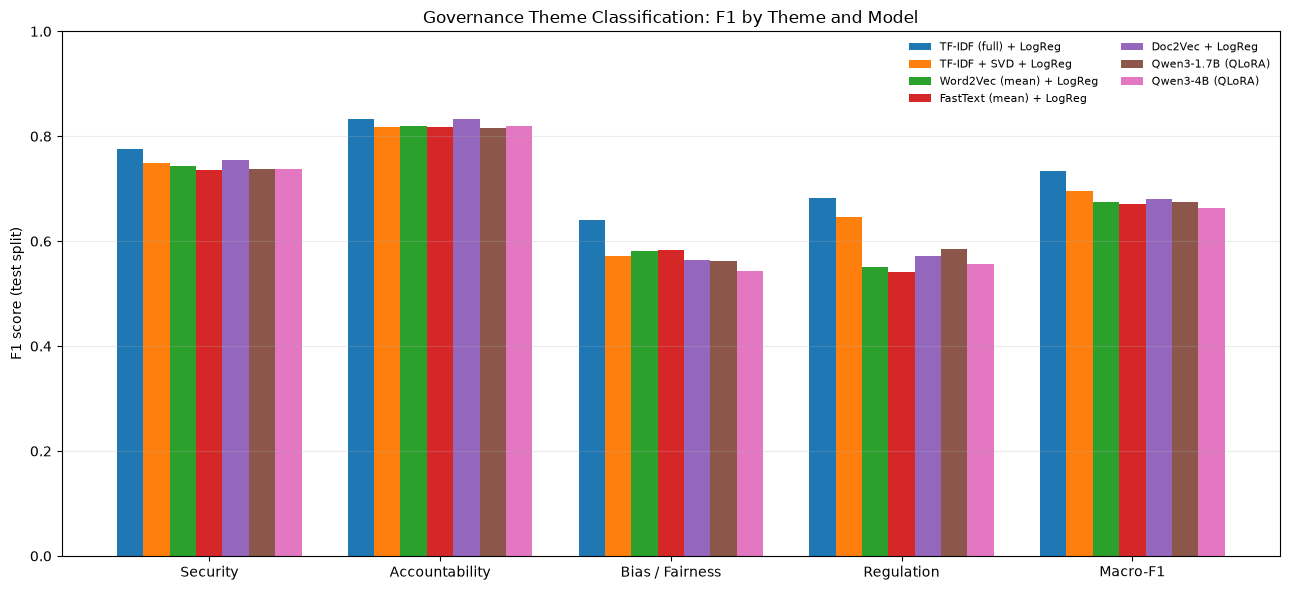

In [18]:
MODEL_ORDER = list(classification_results)

final_results = pd.DataFrame(classification_results).T.loc[MODEL_ORDER]
final_results.to_csv(RESULTS_DIR / "classification_results.csv")

display(final_results.style.highlight_max(axis=0, color="#cde8cd").format("{:.3f}"))

fig, ax = plt.subplots(figsize=(13, 6))
metrics = [THEME_LABELS[t] for t in GOVERNANCE_THEMES] + ["Macro-F1"]
bar_width = 0.8 / len(MODEL_ORDER)
x = np.arange(len(metrics))

for i, model_name in enumerate(MODEL_ORDER):
    ax.bar(x + i * bar_width, final_results.loc[model_name, metrics], width=bar_width, label=model_name)

ax.set_xticks(x + bar_width * (len(MODEL_ORDER) - 1) / 2)
ax.set_xticklabels(metrics)
ax.set_ylabel("F1 score (test split)")
ax.set_ylim(0, 1)
ax.set_title("Governance Theme Classification: F1 by Theme and Model")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("classification_f1_by_model")
plt.show()

**Observations**

- The fine-tuned language models **do not outperform the baselines**: Qwen3-1.7B reaches a macro-F1 of 0.675 and Qwen3-4B 0.664, on the level of the averaged word embeddings and clearly below full TF-IDF (0.733).
- The larger model is not better: the 4B model is equal for Security (0.738), slightly better for Accountability (0.820 vs. 0.815) and worse for Bias/Fairness and Regulation. The overall difference of 0.011 is within the variation of a single training run.
- The most plausible reason is the input length: the language models only see the first 256 tokens of each article, while the baselines use the complete text and the tags may depend on terms anywhere in the article.

### 5.2 Trade-offs: Size, Training Time, Hardware and Speed

Beyond accuracy, the models differ considerably in size, training cost, hardware requirements and inference speed. For the classical models, the training time includes training the embedding (if any) and the logistic regressions; the inference time includes the vectorization of the article text. The language models were trained and run on the 8 GB laptop GPU; all classical models run on the CPU.

In [19]:
inference_sample = [gov_tokens[i] for i in np.where(split_masks["test"])[0][:1000]]


def seconds_per_1000(vectorize):
    start_time = time.perf_counter()
    vectorize(inference_sample)
    return round((time.perf_counter() - start_time) / len(inference_sample) * 1000, 1)


classical_inference = {
    "TF-IDF (full) + LogReg": seconds_per_1000(lambda docs: tfidf.transform(docs)),
    "TF-IDF + SVD + LogReg": seconds_per_1000(lambda docs: svd.transform(tfidf.transform(docs))),
    "Word2Vec (mean) + LogReg": seconds_per_1000(lambda docs: [mean_vector(w2v_model.wv, d) for d in docs]),
    "FastText (mean) + LogReg": seconds_per_1000(lambda docs: [mean_vector(fasttext_model.wv, d) for d in docs]),
    "Doc2Vec + LogReg": seconds_per_1000(lambda docs: [d2v_model.infer_vector(d, epochs=20) for d in docs])
}

embedding_training = {
    "TF-IDF (full) + LogReg": 0,
    "TF-IDF + SVD + LogReg": 0,
    "Word2Vec (mean) + LogReg": training_times.get("Word2Vec", np.nan),
    "FastText (mean) + LogReg": training_times.get("FastText", np.nan),
    "Doc2Vec + LogReg": training_times.get("Doc2Vec", np.nan)
}

classical_parameters = {
    "TF-IDF (full) + LogReg": len(tfidf.vocabulary_) * len(GOVERNANCE_THEMES),
    "TF-IDF + SVD + LogReg": svd.components_.size,
    "Word2Vec (mean) + LogReg": w2v_model.wv.vectors.size,
    "FastText (mean) + LogReg": fasttext_model.wv.vectors.size + fasttext_model.wv.vectors_ngrams.size,
    "Doc2Vec + LogReg": d2v_model.wv.vectors.size + d2v_model.dv.vectors.size
}

from accelerate import init_empty_weights
from transformers import AutoConfig


def nominal_parameter_count(model_id):
    """Parameter count of the unquantized model. In 4-bit layers, bitsandbytes packs two weights
    into one byte, so counting the parameters of the loaded quantized model underestimates the size."""
    with init_empty_weights():
        empty_model = AutoModelForSequenceClassification.from_config(
            AutoConfig.from_pretrained(model_id, num_labels=len(GOVERNANCE_THEMES))
        )
    return sum(p.numel() for p in empty_model.parameters())


llm_parameters = {name: nominal_parameter_count(model_id) for name, model_id in LLM_MODELS.items()}

tradeoff_rows = []
for model_name in MODEL_ORDER:
    if model_name.endswith("(QLoRA)"):
        stats = llm_stats[model_name.replace(" (QLoRA)", "")]
        tradeoff_rows.append({
            "Model": model_name,
            "Hardware": "GPU (8 GB)",
            "Parameters (millions)": round(llm_parameters[model_name.replace(" (QLoRA)", "")] / 1e6),
            "Trained parameters (millions)": round(stats["trainable_parameters"] / 1e6, 1),
            "Training time (min)": stats["training_minutes"],
            "Peak GPU memory (GB)": stats["peak_gpu_memory_gb"],
            "Inference (s per 1,000 articles)": stats["inference_seconds_per_1000"],
            "Macro-F1": final_results.loc[model_name, "Macro-F1"]
        })
    else:
        tradeoff_rows.append({
            "Model": model_name,
            "Hardware": "CPU",
            "Parameters (millions)": round(classical_parameters[model_name] / 1e6, 1),
            "Trained parameters (millions)": round(classical_parameters[model_name] / 1e6, 1),
            "Training time (min)": round((embedding_training[model_name]
                                          + classification_details[model_name]["training_seconds"]) / 60, 1),
            "Peak GPU memory (GB)": 0,
            "Inference (s per 1,000 articles)": classical_inference[model_name],
            "Macro-F1": final_results.loc[model_name, "Macro-F1"]
        })

tradeoffs = pd.DataFrame(tradeoff_rows).set_index("Model")
tradeoffs.to_csv(RESULTS_DIR / "model_tradeoffs.csv")
display(tradeoffs)

,Hardware,Parameters (millions),Trained parameters (millions),Training time (min),Peak GPU memory (GB),"Inference (s per 1,000 articles)",Macro-F1
Model,,,,,,,
TF-IDF (full) + LogReg,CPU,0.2,0.2,0.1,0.00,0.8,0.733
TF-IDF + SVD + LogReg,CPU,10.0,10.0,0.0,0.00,1.1,0.696
Word2Vec (mean) + LogReg,CPU,24.6,24.6,18.7,0.00,3.1,0.674
FastText (mean) + LogReg,CPU,424.6,424.6,59.4,0.00,4.9,0.670
Doc2Vec + LogReg,CPU,33.7,33.7,7.6,0.00,71.7,0.680
Qwen3-1.7B (QLoRA),GPU (8 GB),1721.0,17.4,117.7,2.59,232.8,0.675
Qwen3-4B (QLoRA),GPU (8 GB),4022.0,33.0,150.8,5.16,1152.7,0.664


**Observations**

- The classical models train in seconds to an hour on a CPU; the language models need two to two and a half hours on a GPU.
- At inference, the gap is even larger: full TF-IDF classifies 1,000 articles in about one second, Qwen3-1.7B in about four minutes and Qwen3-4B in about 19 minutes.
- For this task, full TF-IDF therefore offers the **best quality at the lowest cost**. The larger language model is more expensive in every respect (parameters, memory, speed) without a gain in F1.

### 5.3 Comparing the Learned Representations

Section 2.6 compared the classical document representations. Here, the representations of the language models are added: the last-token hidden state of each test article, once from the **original** Qwen model and once from the **fine-tuned** model. The silhouette score again measures how well articles with a single Governance theme are separated by theme, and the UMAP projections show the separation visually.

,"Silhouette (Governance themes, test split)"
TF-IDF + SVD,0.024
Doc2Vec,0.018
Qwen3-1.7B (original),-0.007
Qwen3-1.7B (fine-tuned),0.068
Qwen3-4B (original),-0.007
Qwen3-4B (fine-tuned),0.129


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


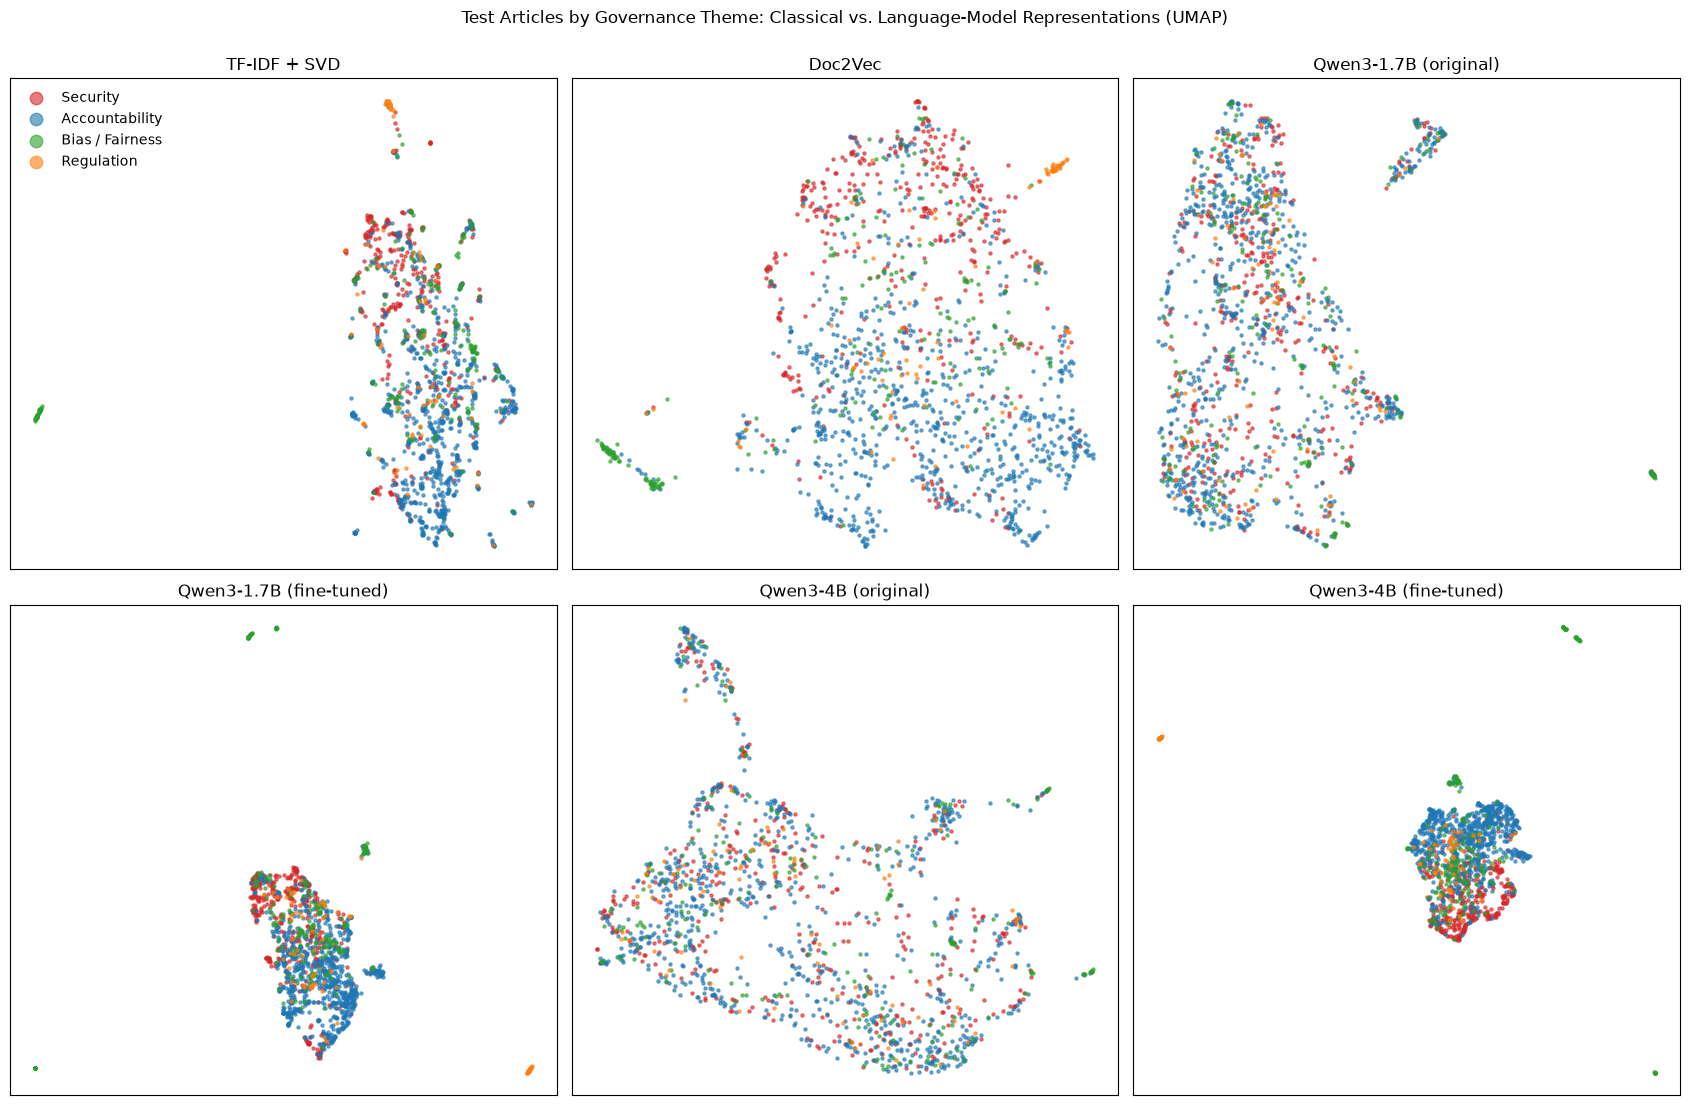

In [20]:
test_index = np.where(split_masks["test"])[0]
test_single = single_theme[test_index]
test_theme = single_theme_label[test_index][test_single]

test_representations = {
    "TF-IDF + SVD": doc_vectors["tfidf_svd"][test_index],
    "Doc2Vec": doc_vectors["doc2vec"][test_index]
}
for name in LLM_MODELS:
    test_representations[f"{name} (original)"] = llm_predictions[name]["test_embeddings_base"]
    test_representations[f"{name} (fine-tuned)"] = llm_predictions[name]["test_embeddings_finetuned"]

representation_scores = pd.DataFrame({
    "Silhouette (Governance themes, test split)": {
        name: round(silhouette_score(normalize(matrix[test_single]), test_theme, metric="cosine"), 3)
        for name, matrix in test_representations.items()
    }
})
representation_scores.to_csv(RESULTS_DIR / "representation_silhouette.csv")
display(representation_scores)

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
for ax, (name, matrix) in zip(axes.ravel(), test_representations.items()):
    coordinates = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED) \
        .fit_transform(normalize(matrix[test_single]))
    for theme_index, theme in enumerate(GOVERNANCE_THEMES):
        mask = test_theme == theme_index
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=5, alpha=0.6,
                   color=theme_colors[theme_index], label=THEME_LABELS[theme])
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].legend(markerscale=4, frameon=False)
fig.suptitle("Test Articles by Governance Theme: Classical vs. Language-Model Representations (UMAP)", y=1.0)
plt.tight_layout()
save_figure("representations_classical_vs_llm_umap")
plt.show()

**Observations**

- Before fine-tuning, the representations of both Qwen models do **not separate the themes** (silhouette −0.007), i.e. the general-purpose language model does not organize articles by Governance theme.
- After fine-tuning, the silhouette rises to 0.068 (1.7B) and 0.129 (4B), clearly above TF-IDF + SVD (0.024) and Doc2Vec (0.018). The UMAP of the fine-tuned 4B model shows a compact cloud with Accountability on one side and Security on the other.
- The 4B model therefore learns the most theme-structured representation, although this does not lead to a higher F1. The representation and the classification quality measure different things.

## 6. Insight Extraction for AI Governance

### 6.1 Governance Content Beyond the Tags

In Stage 1, Governance articles were selected exclusively via dataset tags, and the limitations noted that relevant articles without matching tags may be missed. The trained models make it possible to examine this.

The theme classifier from Sections 3–5 was trained only on Governance articles and therefore cannot recognize articles *without* Governance content. A two-step approach is used instead:

1. **Relevance detection.** A TF-IDF + logistic-regression classifier distinguishes Governance-tagged articles (positives) from untagged articles (negatives). To score every untagged article without training on it, the untagged articles are split into five folds; each fold is scored by a model trained on the other four (cross-fitting). Untagged articles with a high score are **candidates**: their wording resembles Governance coverage although they carry no Governance tag.
2. **Theme assignment.** The candidates are classified into the four Governance themes with the better of the two fine-tuned language models from Section 5 (Qwen3-1.7B). Full TF-IDF reached a higher macro-F1, but it is closely related to the TF-IDF features of the relevance detector; the language model adds a second, independent view of the candidate texts.

Because some untagged articles are in fact about Governance, the "negatives" are noisy; the detector's precision is therefore a conservative estimate.

In [21]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import KFold

RELEVANCE_PATH = RESULTS_DIR / "governance_relevance_scores.csv"

untagged_index = np.where(corpus["split"].values == "unlabelled")[0]
positive_train_index = np.where(corpus["split"].values == "train")[0]
positive_validation_index = np.where(corpus["split"].values == "validation")[0]
positive_test_index = np.where(corpus["split"].values == "test")[0]

if RELEVANCE_PATH.exists():
    relevance = pd.read_csv(RELEVANCE_PATH)
    print("Relevance scores loaded from cache.")
else:
    relevance_vectorizer = TfidfVectorizer(analyzer=identity, min_df=5, max_df=0.8, max_features=50000, sublinear_tf=True)
    relevance_vectorizer.fit([article_tokens[i] for i in np.concatenate([positive_train_index, untagged_index])])
    X_all = relevance_vectorizer.transform(article_tokens)

    untagged_scores = np.zeros(len(untagged_index))
    validation_scores_folds, test_scores_folds = [], []

    for fold_train, fold_score in KFold(n_splits=5, shuffle=True, random_state=SEED).split(untagged_index):
        train_rows = np.concatenate([positive_train_index, untagged_index[fold_train]])
        train_labels = np.concatenate([np.ones(len(positive_train_index)), np.zeros(len(fold_train))])
        detector = LogisticRegression(max_iter=3000, class_weight="balanced", C=4.0)
        detector.fit(X_all[train_rows], train_labels)
        untagged_scores[fold_score] = detector.predict_proba(X_all[untagged_index[fold_score]])[:, 1]
        validation_scores_folds.append(detector.predict_proba(X_all[positive_validation_index])[:, 1])
        test_scores_folds.append(detector.predict_proba(X_all[positive_test_index])[:, 1])

    relevance = pd.DataFrame({
        "record_id": corpus["record_id"].values[np.concatenate(
            [untagged_index, positive_validation_index, positive_test_index])],
        "group": ["untagged"] * len(untagged_index) + ["validation"] * len(positive_validation_index)
                 + ["test"] * len(positive_test_index),
        "score": np.concatenate([untagged_scores, np.mean(validation_scores_folds, axis=0),
                                 np.mean(test_scores_folds, axis=0)])
    })
    relevance.to_csv(RELEVANCE_PATH, index=False)

# Threshold: F1-optimal separation of validation positives from untagged articles
validation_scores = relevance.loc[relevance["group"] == "validation", "score"].values
untagged_scores = relevance.loc[relevance["group"] == "untagged", "score"].values
test_scores = relevance.loc[relevance["group"] == "test", "score"].values

candidates_t = np.linspace(0.05, 0.95, 91)
threshold_f1 = [
    f1_score(np.r_[np.ones(len(validation_scores)), np.zeros(len(untagged_scores))],
             np.r_[validation_scores, untagged_scores] >= t)
    for t in candidates_t
]
RELEVANCE_THRESHOLD = candidates_t[int(np.argmax(threshold_f1))]

y_detect = np.r_[np.ones(len(test_scores)), np.zeros(len(untagged_scores))]
s_detect = np.r_[test_scores, untagged_scores]

relevance_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC (tagged test articles vs. untagged)",
        "Recall of tagged test articles",
        "Precision w.r.t. tags (conservative)",
        "Decision threshold",
        "Untagged articles",
        "Untagged articles detected as Governance-related (candidates)"
    ],
    "Result": [
        round(roc_auc_score(y_detect, s_detect), 3),
        round(recall_score(y_detect, s_detect >= RELEVANCE_THRESHOLD), 3),
        round(precision_score(y_detect, s_detect >= RELEVANCE_THRESHOLD), 3),
        round(RELEVANCE_THRESHOLD, 2),
        len(untagged_scores),
        int((untagged_scores >= RELEVANCE_THRESHOLD).sum())
    ]
})
display(relevance_summary)

candidate_ids = relevance.loc[
    (relevance["group"] == "untagged") & (relevance["score"] >= RELEVANCE_THRESHOLD), "record_id"
]
candidates = corpus.loc[corpus["record_id"].isin(candidate_ids)].merge(
    relevance[["record_id", "score"]], on="record_id"
).sort_values("score", ascending=False)

print("\nHighest-scoring untagged articles:")
with pd.option_context("display.max_colwidth", 100):
    display(candidates[["record_id", "date", "domain", "title", "score"]].head(15))

Relevance scores loaded from cache.


,Metric,Result
0,ROC-AUC (tagged test articles vs. untagged),0.932
1,Recall of tagged test articles,0.533
2,Precision w.r.t. tags (conservative),0.649
3,Decision threshold,0.780
4,Untagged articles,34733.000
5,Untagged articles detected as Governance-relat...,561.000



Highest-scoring untagged articles:


,record_id,date,domain,title,score
518,127669,2026-06-26,sciencenews,"How big a cybersecurity threat are the latest AI models, really?",0.992703
215,45811,2025-07-17,aijourn,Who Owns AI-Generated Creativity? Rethinking Copyright in the Age of Co-Creation,0.992372
552,127706,2026-08-07,sciencenews,AI may respond differently to bosses and subordinates,0.991107
237,45916,2025-08-08,aijourn,Why responsible AI innovation is key to the future of UK public services,0.990026
35,41182,2024-10-28,csis,The Executive Action on Sensitive Bulk and Government-Related Data Sales to Adversary Nations,0.983986
500,77042,2026-06-10,anthropic,Policy on the AI Exponential \ Anthropic,0.982293
198,41455,2025-06-17,csis,Norms in New Technological Domains: What’s Next for Japan and the United States in Cyberspace,0.980295
437,168373,2026-04-23,hiddenlayer,Key Security Questions for Protecting AI Agents,0.980085
202,20424,2025-06-19,aithority,"In the Age of AI, Trust Is the Real Infrastructure",0.977546
131,173739,2025-03-25,swisscognitive,Is Healthcare AI Prioritizing People or Profit? - SwissCognitive,0.976374


**Observations**

- The relevance detector separates Governance and non-Governance articles well (ROC-AUC 0.932). At the chosen threshold it is conservative: it recovers about half of the tagged test articles (recall 0.533).
- **561 untagged articles** (1.6% of all untagged articles) are flagged as candidates. The highest-scoring ones are clearly about Governance (e.g. cybersecurity threats of AI models, copyright of AI-generated content, responsible AI in public services, AI policy), so the tags do miss some relevant coverage.
- Not all candidates are correct: a *Privacy and Cookie Policy* page also scores high, because it uses Governance vocabulary.

### 6.2 Theme Assignment for the Candidate Articles

The candidates are classified into the four Governance themes with the best language model from Section 5 (highest macro-F1), using the thresholds tuned on the validation split.

In [22]:
llm_names = [name for name in MODEL_ORDER if name.endswith("(QLoRA)")]
best_llm = max(llm_names, key=lambda name: final_results.loc[name, "Macro-F1"])
best_llm_key = best_llm.replace(" (QLoRA)", "")
best_thresholds = tune_thresholds(y["validation"], llm_predictions[best_llm_key]["validation_scores"])
print(f"Theme classifier: {best_llm} (macro-F1 {final_results.loc[best_llm, 'Macro-F1']:.3f})")

CANDIDATE_THEMES_PATH = RESULTS_DIR / f"candidate_theme_predictions_{best_llm_key}.csv"
cached = pd.read_csv(CANDIDATE_THEMES_PATH) if CANDIDATE_THEMES_PATH.exists() else None
if cached is not None and set(cached["record_id"]) == set(candidates["record_id"]):
    candidate_scores = cached[[f"score_{t}" for t in GOVERNANCE_THEMES]].values
    candidate_order = cached["record_id"].values
    print("Candidate predictions loaded from cache.")
else:
    tokenizer, base_model = load_quantized_classifier(LLM_MODELS[best_llm_key])
    model = PeftModel.from_pretrained(base_model, MODELS_DIR / f"qlora_{best_llm_key}")
    start_time = time.perf_counter()
    candidate_scores = predict(model, tokenizer, (candidates["title"] + ". " + candidates["content_text"]).tolist())
    print(f"Inference for {len(candidates):,} articles: {(time.perf_counter() - start_time) / 60:.1f} min")
    candidate_order = candidates["record_id"].values
    pd.DataFrame(
        {"record_id": candidate_order, **{f"score_{t}": candidate_scores[:, k] for k, t in enumerate(GOVERNANCE_THEMES)}}
    ).to_csv(CANDIDATE_THEMES_PATH, index=False)
    del model, base_model
    gc.collect()
    torch.cuda.empty_cache()

candidate_predictions = pd.DataFrame(
    (candidate_scores >= best_thresholds).astype(int), columns=GOVERNANCE_THEMES
)
candidate_predictions.insert(0, "record_id", candidate_order)

theme_extension = pd.DataFrame({
    "Tagged Governance articles": corpus.loc[corpus["governance_related"], GOVERNANCE_THEMES].sum(),
    "Additional candidates (predicted)": candidate_predictions[GOVERNANCE_THEMES].sum()
}).rename(index=THEME_LABELS)
theme_extension["Increase (%)"] = (
    theme_extension["Additional candidates (predicted)"] / theme_extension["Tagged Governance articles"] * 100
).round(1)
display(theme_extension)

Theme classifier: Qwen3-1.7B (QLoRA) (macro-F1 0.675)
Candidate predictions loaded from cache.


,Tagged Governance articles,Additional candidates (predicted),Increase (%)
Security,4455,254,5.7
Accountability,7592,413,5.4
Bias / Fairness,2662,102,3.8
Regulation,1370,44,3.2


**Observations**

- Adding the candidates increases the theme counts by only **3–6%**: Security +254 (5.7%), Accountability +413 (5.4%), Bias/Fairness +102 (3.8%), Regulation +44 (3.2%).
- Most candidates are assigned to Security and Accountability. The tags therefore miss mainly articles on these two broad themes, and only few on Regulation.

### 6.3 Governance Trends With and Without the Candidates

If the tags systematically missed Governance coverage in some periods, adding the candidate articles would change the temporal development observed in Stage 1. The figure compares the monthly share of each Governance theme based on tags only with the share based on tags plus the predicted candidates.

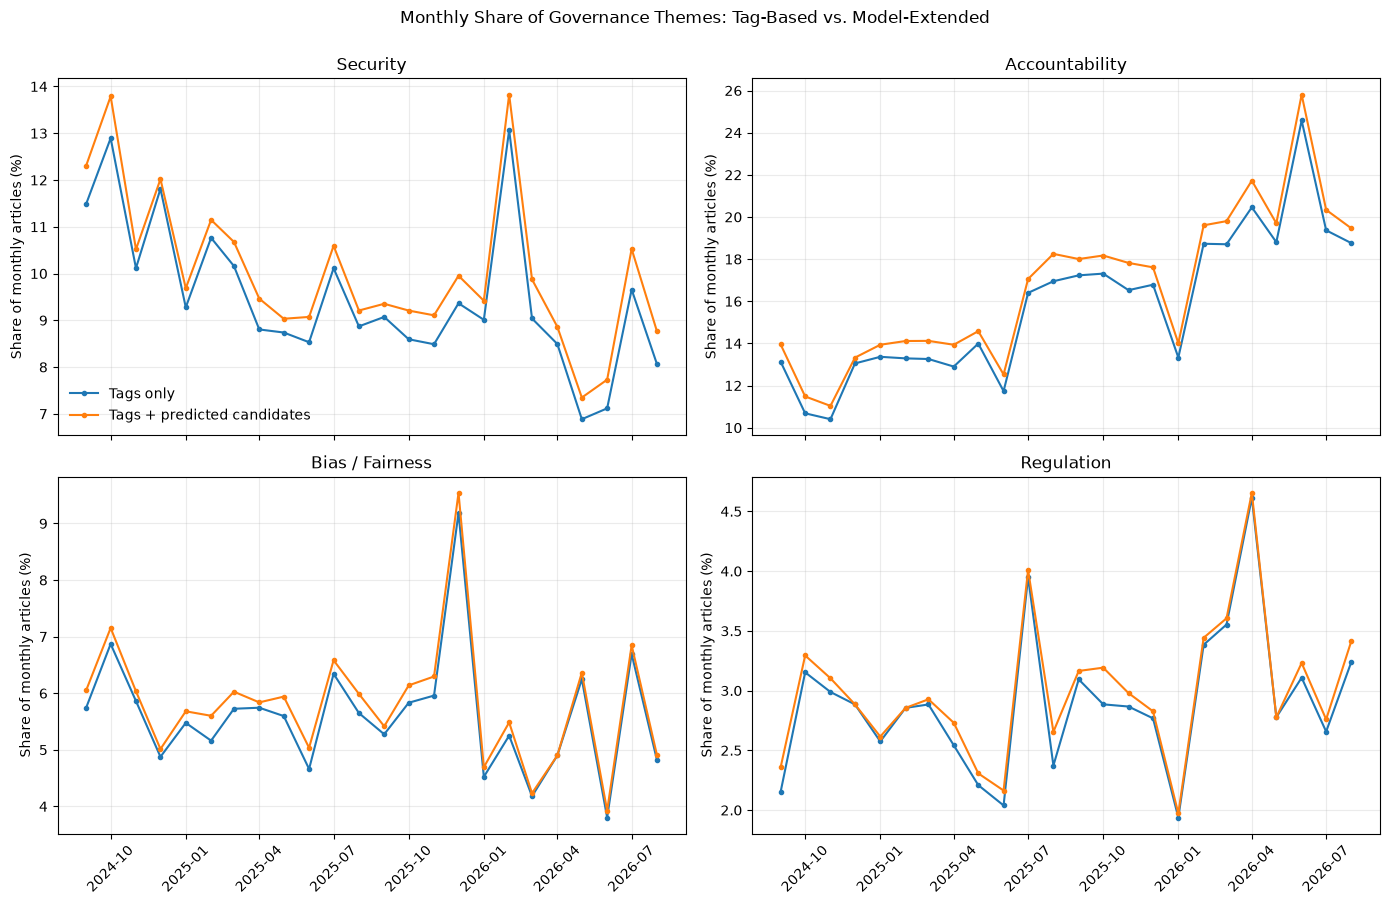

,Tags: first 3 months (%),Tags: last 3 months (%),Extended: first 3 months (%),Extended: last 3 months (%)
Security,11.50,8.28,12.20,9.01
Accountability,11.40,20.90,12.16,21.87
Bias / Fairness,6.16,5.11,6.41,5.23
Regulation,2.77,3.00,2.92,3.14


In [23]:
monthly = corpus[["record_id", "date"] + GOVERNANCE_THEMES].copy()
monthly = monthly[(monthly["date"] >= "2024-09-01") & (monthly["date"] <= "2026-08-31")]
monthly["month"] = monthly["date"].dt.to_period("M").dt.to_timestamp()

extended = monthly.set_index("record_id")[GOVERNANCE_THEMES].astype(int)
predicted = candidate_predictions.set_index("record_id")[GOVERNANCE_THEMES]
predicted = predicted[predicted.index.isin(extended.index)]
extended.loc[predicted.index] = extended.loc[predicted.index].values | predicted.values
extended["month"] = monthly.set_index("record_id")["month"]

total_per_month = monthly.groupby("month").size()
share_tags = monthly.groupby("month")[GOVERNANCE_THEMES].sum().div(total_per_month, axis=0) * 100
share_extended = extended.groupby("month")[GOVERNANCE_THEMES].sum().div(total_per_month, axis=0) * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, theme in zip(axes.ravel(), GOVERNANCE_THEMES):
    ax.plot(share_tags.index, share_tags[theme], marker="o", markersize=3, label="Tags only")
    ax.plot(share_extended.index, share_extended[theme], marker="o", markersize=3, label="Tags + predicted candidates")
    ax.set_title(THEME_LABELS[theme])
    ax.set_ylabel("Share of monthly articles (%)")
    ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Monthly Share of Governance Themes: Tag-Based vs. Model-Extended", y=1.0)
plt.tight_layout()
save_figure("governance_trends_tags_vs_model")
plt.show()

trend_comparison = pd.DataFrame({
    "Tags: first 3 months (%)": share_tags.iloc[:3].mean(),
    "Tags: last 3 months (%)": share_tags.iloc[-3:].mean(),
    "Extended: first 3 months (%)": share_extended.iloc[:3].mean(),
    "Extended: last 3 months (%)": share_extended.iloc[-3:].mean()
}).rename(index=THEME_LABELS).round(2)
display(trend_comparison)

**Observations**

- The extended curves run almost parallel to the tag-based curves and are only slightly higher, mainly for Security and Accountability.
- **No trend changes direction**: Accountability rises from 11.4% to 20.9% of the monthly articles with tags alone and from 12.2% to 21.9% with the candidates; Security declines in both cases (11.5% → 8.3% and 12.2% → 9.0%). Bias/Fairness and Regulation hardly change.
- The Governance trends from Stage 1 are therefore **robust against missing tags**.

## 7. Summary

### Stage 2 Key Findings

1. **Classical embeddings capture the Governance vocabulary well.** The nearest neighbours of terms such as *accountability*, *bias* or *deepfake* are semantically coherent (e.g. *bias* → *algorithmic_bias*, *bias_discrimination*). In the word-pair test, both Word2Vec and FastText rank every related pair above every unrelated pair (pairwise accuracy 1.0); FastText separates the two groups slightly more clearly (mean similarity 0.64 vs. 0.14).
2. **The meaning of *agent* changed most between the two periods.** Its neighbour overlap is only 0.08: in the first year it is associated with *ai_agents*, *mcp_client* and *coding_agent*, in the second year with *sub-agent*, *subagent* and *agent_executes*, i.e. with the internal structure of multi-agent systems. This mirrors the rise of the agent topic in the Stage 1 topic model (from 1.5 % to 16.9 %). *Regulation* (0.21) moves towards *eu_regulation* and *act's*, *accountability* (0.25) towards *decision_rights*, *high-stakes_decisions* and *ethical_oversight*, *security* towards *zero-trust_security*, *posture_management* and *secure-by-design*. *Copyright* and *China* remain the most stable terms (0.38).
3. **For theme classification, the sparse TF-IDF representation is the strongest model.** Full TF-IDF with logistic regression reaches a macro-F1 of 0.733 on the test split. The dense 200-dimensional representations (TF-IDF + SVD, Word2Vec, FastText, Doc2Vec) reach 0.67–0.70; they lose mainly on the rare Regulation theme (0.54–0.65 vs. 0.68), whose articles are recognisable by specific terms that disappear when word vectors are averaged.
4. **The fine-tuned language models do not outperform the classical baselines on this task.** Qwen3-1.7B reaches a macro-F1 of 0.675 and Qwen3-4B 0.664 – on the level of the averaged word embeddings and clearly below full TF-IDF. The larger model is not better: it has 2.3 times as many parameters, needs twice the GPU memory (5.2 vs. 2.6 GB) and is about five times slower at inference. The most plausible reason is the input limit of 256 tokens (median article length after preprocessing: 596 tokens), while the tags depend on terms anywhere in the article.
5. **Fine-tuning nevertheless restructures the language-model representations.** Before fine-tuning, the last-token embeddings of both Qwen models do not separate the Governance themes (silhouette −0.007). After fine-tuning, the silhouette rises to 0.068 (1.7B) and 0.129 (4B), clearly above TF-IDF + SVD (0.024) and Doc2Vec (0.018). The fine-tuned 4B model therefore learns the most theme-structured representation, even though this does not translate into a higher F1.
6. **Trade-off.** With respect to the effort, the classical models are clearly preferable for this task: full TF-IDF trains in seconds on a CPU and classifies 1,000 articles in about one second, while QLoRA fine-tuning took two to two and a half hours on an 8 GB laptop GPU and its inference takes four to 19 minutes per 1,000 articles.
7. **The Governance trends from Stage 1 are robust against missing tags.** The relevance detector (ROC-AUC 0.93) finds 561 untagged articles (1.6 % of the untagged articles) whose wording resembles Governance coverage. Adding them with the themes predicted by Qwen3-1.7B increases the theme counts by only 3–6 % and does not change the direction of any trend: Accountability rises from 11.4 % to 20.9 % of the monthly articles based on tags alone and from 12.2 % to 21.9 % with the candidates, while Security declines in both cases (11.5 % → 8.3 % and 12.2 % → 9.0 %).
8. **Which representations capture the Governance developments most effectively?** For detecting and classifying Governance articles, sparse lexical features (TF-IDF) are the most effective and cheapest representation. For describing *how* the discourse changes (vocabulary, semantic shift), the word embeddings are most informative. The fine-tuned language models provide the most clearly theme-structured document representations, but at a much higher cost and without a gain in classification quality under the given input limit.

### Limitations

- **Labels.** The theme labels are the tags of the dataset, not manual annotations. They appear to depend strongly on keywords, which favours lexical models such as TF-IDF. Untagged articles are not necessarily unrelated to Governance, so the precision of the relevance detector with respect to the tags is a conservative estimate; the 561 candidates were not checked manually.
- **Input length of the language models.** For time reasons, the language models see only the title and the first 256 tokens of each article, while the baselines use the complete text. A comparison with longer inputs (e.g. 512 tokens) could change the ranking, but would roughly double the training time.
- **Training setup.** Each model was trained once (one seed, one epoch) without a hyperparameter search; small differences such as 0.675 vs. 0.664 are therefore within the expected variation and should not be over-interpreted.
- **Hardware.** All timings were measured on a single laptop GPU (RTX 2000 Ada, 8 GB) that was thermally throttled during the QLoRA runs. The absolute training and inference times are therefore specific to this setup; the inference time of Qwen3-4B is additionally affected by its high memory use close to the 8 GB limit.
- **Phrase detection.** The statistical phrase detection did not merge *EU AI Act* into one token, because *ai* is too frequent in the corpus. Multi-word names of laws and standards are therefore partly split into separate words.
- **Semantic shift.** The two period models are trained separately and compared via the overlap of their nearest neighbours, without aligning the vector spaces. The overlap values depend on random initialisation and on the frequency of a term in each period and are therefore indicative only.
- **Word-pair test.** The intrinsic evaluation uses a small, manually compiled set of 30 word pairs; it shows that the embeddings capture the Governance vocabulary, but does not allow a fine-grained comparison of Word2Vec and FastText.

### Use of AI Tools

The group used generative AI tools during Stage 2, in accordance with the project requirements:

| AI tool | Use |
|---|---|
| Claude | Development, reviews and documentation |
| ChatGPT | Development support: code review, debugging, methodological discussion and documentation |

AI-generated suggestions were reviewed before implementation, and modelling decisions (models, hyperparameters, evaluation protocol) as well as the interpretation of the results were validated against the data and the project requirements. All reported numbers originate from the executed notebook.

## Contributions

### Stage 2 – AI Governance

- **Michael Nguyen** implemented and documented Stage 2.
- **Dana Srdic** and **Henrik Szent-Ivany** reviewed the notebook and contributed corrections and extensions.